# Ranking-loss follow-up with test-set evaluation (full dataset)

Twelve runs: four configurations $\times$ three seeds (7, 17, 27), 20 epochs each (design: `RANK_FOLLOWUP_FULL.md`).
The within-target ranking loss is now standard: every configuration is the control recipe (fixed loss weights,
dropout 0.3, capped inverse-sqrt range weighting, combined pooling, cosine over 20 epochs) plus the ranking loss
(weight 0.1) with grouped batches of 4 targets $\times$ 4 decoys, and one further change:

| config | change |
|---|---|
| rank | none: the reference |
| rank\_capri | + CAPRI-class head (cross-entropy weight 0.2) |
| rank\_lambda3 | reconstruction weight $\lambda = 3$ |
| rank\_lr1e-4 | peak learning rate $10^{-4}$ instead of $3\times10^{-4}$ |

**First use of the test split.** The 29 test targets (34,704 decoys) were sealed during training. After training,
each run reloaded the checkpoint with the lowest validation DockQ MSE (validations every 2,000 steps and at epoch
ends) and evaluated it once on the test targets. That selection rule was fixed in advance and every run was
evaluated, so all four configurations are reported on test together. The test cohort is the same one the feature
ladder was evaluated on, which allows a direct before/after comparison on held-out targets.

Figures use LaTeX Computer Modern, large labels, full borders and no titles. Spreads are SD over seeds; paired
intervals are bootstraps over targets (12 validation, 29 test).

In [1]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown

if shutil.which('latex') is None:
    raise RuntimeError('LaTeX is required to render the figures in Computer Modern.')
GATE = Path.cwd() if (Path.cwd() / 'rank_followup_full').is_dir() else Path.cwd() / 'gate_run'
ROOT = GATE / 'rank_followup_full'
LADDER = GATE / 'feature_ladder_full'
EXPORT = GATE / 'rank_followup_full_analysis'; EXPORT.mkdir(exist_ok=True)
EPOCHS, SEEDS = 20, [7, 17, 27]
CONFIGS = ['rank', 'rank_capri', 'rank_lambda3', 'rank_lr1e-4']
LABEL = {'rank': 'Rank', 'rank_capri': 'Rank + CAPRI head', 'rank_lambda3': r'Rank + $\lambda = 3$',
         'rank_lr1e-4': r'Rank + LR $10^{-4}$'}
SHORT = {'rank': 'Rank', 'rank_capri': '+CAPRI', 'rank_lambda3': r'+$\lambda$=3', 'rank_lr1e-4': r'+LR $10^{-4}$'}
COLOR = {'rank': '#000000', 'rank_capri': '#D55E00', 'rank_lambda3': '#56B4E9', 'rank_lr1e-4': '#009E73'}
CAPRI = (0.23, 0.49, 0.80)
CAPRI_NAMES = ['incorrect', 'acceptable', 'medium', 'high']

mpl.rcParams.update({'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'],
    'mathtext.fontset': 'cm', 'axes.labelsize': 23, 'xtick.labelsize': 17, 'ytick.labelsize': 17,
    'legend.fontsize': 17, 'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 1.1})

def save(fig, name):
    fig.savefig(EXPORT / (name + '.pdf'), bbox_inches='tight')
    fig.savefig(EXPORT / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()

def run_dir(config, seed):
    return ROOT / f'{config}_seed{seed}'

steps, history, val_pred, test_pred, reports, recon = [], [], {}, {}, {}, []
for config in CONFIGS:
    for seed in SEEDS:
        d = run_dir(config, seed)
        s = pd.read_csv(d / 'validation_steps.csv').assign(config=config, seed=seed)
        h = pd.read_csv(d / 'loss_history.csv').assign(config=config, seed=seed)
        if h.epoch.max() != EPOCHS:
            raise ValueError(f'{d.name}: finished {h.epoch.max()} of {EPOCHS} epochs')
        if not h.filter(regex='^test_').isna().all().all():
            raise ValueError(f'{d.name}: test split was evaluated during training')
        spe = s[(s.end_of_epoch == 1) & (s.epoch == 1)].global_step.iloc[0]
        s['epoch_float'] = s.global_step / spe
        v = pd.read_csv(d / 'validation_predictions.csv'); t = pd.read_csv(d / 'test_predictions.csv')
        rep = json.loads((d / 'prediction_metrics.json').read_text())
        if not np.isclose(np.mean((v.predicted_target - v.true_target) ** 2), s.val_target_mse.min(), rtol=1e-5, atol=1e-7):
            raise ValueError(f'{d.name}: validation predictions are not from the best validation checkpoint')
        if not np.isclose(rep['selected_checkpoint']['validation_target_mse'], s.val_target_mse.min(), rtol=1e-5):
            raise ValueError(f'{d.name}: the tested checkpoint is not the best validation checkpoint')
        if not np.isclose(np.mean((t.predicted_target - t.true_target) ** 2), rep['test']['pooled_mse'], rtol=1e-6):
            raise ValueError(f'{d.name}: test predictions and test metrics disagree')
        steps.append(s); history.append(h); val_pred[config, seed] = v; test_pred[config, seed] = t; reports[config, seed] = rep
        recon.append(pd.read_csv(d / 'reconstruction_summary.csv').assign(config=config, seed=seed))
steps = pd.concat(steps, ignore_index=True); history = pd.concat(history, ignore_index=True)
recon = pd.concat(recon, ignore_index=True)

val_ref = val_pred['rank', 7][['target_id', 'graph_name', 'true_target']]
test_ref = test_pred['rank', 7][['target_id', 'graph_name', 'true_target']]
for preds, ref, name in [(val_pred, val_ref, 'validation'), (test_pred, test_ref, 'test')]:
    for key, p in preds.items():
        if not (p.graph_name.equals(ref.graph_name) and np.allclose(p.true_target, ref.true_target)):
            raise ValueError(f'{key}: {name} cohort or labels differ')
if set(val_ref.target_id) & set(test_ref.target_id):
    raise ValueError('validation and test targets overlap')
ladder_test = {(r, s): pd.read_csv(LADDER / f'gat4_residual_{r}_seed{s}' / 'test_predictions.csv')
               for r in ('core', 'electrostatics') for s in SEEDS}
same = set(zip(ladder_test['electrostatics', 7].target_id, ladder_test['electrostatics', 7].graph_name)) == \
       set(zip(test_ref.target_id, test_ref.graph_name))
print(f'{len(test_pred)} runs, {EPOCHS} epochs each; test sealed during training in every run.')
print(f'Validation: {len(val_ref):,} decoys / {val_ref.target_id.nunique()} targets. '
      f'Test: {len(test_ref):,} decoys / {test_ref.target_id.nunique()} targets; disjoint from validation.')
print(f'Tested checkpoint = best validation checkpoint in every run. Test cohort identical to the feature ladder: {same}.')

12 runs, 20 epochs each; test sealed during training in every run.
Validation: 14,155 decoys / 12 targets. Test: 34,704 decoys / 29 targets; disjoint from validation.
Tested checkpoint = best validation checkpoint in every run. Test cohort identical to the feature ladder: True.


## Reference points

A constant predictor at each set's own mean has MSE equal to that set's label variance (optimistic: it uses the
labels). For decoy selection, a random pick per target gives the target's mean DockQ, and an oracle gives its best.

In [2]:
def refs(ref):
    g = ref.groupby('target_id').true_target
    return dict(const_mse=ref.true_target.var(ddof=0), random_top1=g.mean().mean(), oracle_top1=g.max().mean())
REF = {'validation': refs(val_ref), 'test': refs(test_ref)}
display(pd.DataFrame(REF).T.round(4))

,const_mse,random_top1,oracle_top1
validation,0.0903,0.3228,0.8918
test,0.0967,0.3341,0.9050


## Metrics at the selected checkpoint

Computed identically for validation and test from the exported predictions. Macro metrics weight targets equally;
$\langle\rho\rangle$ is within-target Spearman; top-1 is the true DockQ of each target's top-ranked decoy; high
recall / precision use true and predicted DockQ $\geq 0.80$; high bias is the mean error on true high decoys.

In [3]:
def capri_of(v):
    return np.searchsorted(CAPRI, v, side='right')

def metrics_of(p):
    y = p.true_target.to_numpy(); f = p.predicted_target.to_numpy(); hi = y >= .8; ph = f >= .8
    per_t = p.groupby('target_id')[['graph_name', 'true_target', 'predicted_target']].apply(lambda g: pd.Series(dict(
        rho=spearmanr(g.true_target, g.predicted_target).statistic,
        top1=g.true_target.to_numpy()[np.lexsort((g.graph_name.to_numpy(), -g.predicted_target.to_numpy()))[0]],
        mse=np.mean((g.predicted_target - g.true_target) ** 2))))
    out = dict(mse=np.mean((f - y) ** 2), macro_mse=per_t.mse.mean(), macro_rho=per_t.rho.mean(), top1=per_t.top1.mean(),
               high_recall=ph[hi].mean(), high_precision=hi[ph].mean() if ph.any() else np.nan, n_pred_high=int(ph.sum()),
               high_bias=(f - y)[hi].mean(), low_bias=(f - y)[y < .23].mean(), capri_acc=(capri_of(f) == capri_of(y)).mean(),
               high_auc=roc_auc_score(hi, f))
    return out, per_t

rows, per_target = [], []
for split, preds in [('validation', val_pred), ('test', test_pred)]:
    for (config, seed), p in preds.items():
        m, per_t = metrics_of(p)
        rows.append(dict(split=split, config=config, seed=seed, best_epoch=reports[config, seed]['selected_checkpoint']['best_epoch'], **m))
        per_target.append(per_t.reset_index().assign(split=split, config=config, seed=seed))
metrics = pd.DataFrame(rows); per_target = pd.concat(per_target, ignore_index=True)
metrics.to_csv(EXPORT / 'metrics_per_run.csv', index=False); per_target.to_csv(EXPORT / 'metrics_per_target.csv', index=False)
COLS = ['mse', 'macro_mse', 'macro_rho', 'top1', 'high_recall', 'high_precision', 'n_pred_high', 'high_bias', 'low_bias',
        'capri_acc', 'high_auc', 'best_epoch']
agg = metrics.groupby(['split', 'config'])[COLS].agg(['mean', 'std'])
agg.to_csv(EXPORT / 'metrics_by_config.csv')
display(metrics.groupby(['split', 'config'])[COLS].mean().reindex(CONFIGS, level=1).round(4))

mse  macro_mse  macro_rho    top1  high_recall  \
split      config                                                            
test       rank          0.0586     0.0592     0.6857  0.4471       0.0921   
           rank_capri    0.0599     0.0605     0.6757  0.4689       0.0704   
           rank_lambda3  0.0606     0.0609     0.6594  0.4068       0.0458   
           rank_lr1e-4   0.0604     0.0614     0.6609  0.4353       0.1267   
validation rank          0.0470     0.0501     0.7278  0.4567       0.0685   
           rank_capri    0.0455     0.0478     0.7361  0.4814       0.0946   
           rank_lambda3  0.0494     0.0518     0.7103  0.5264       0.0341   
           rank_lr1e-4   0.0460     0.0481     0.7236  0.4860       0.1057   

                         high_precision  n_pred_high  high_bias  low_bias  \
split      config                                                           
test       rank                  0.4924     812.6667    -0.2976    0.1501   
           rank_capri            0.4480     654.6667    -0.3066    0.1242   
           rank_lambda3          0.4498     442.0000    -0.3142    0.1658   
           rank_lr1e-4           0.4927    1134.6667    -0.2630    0.1577   
validation rank                  0.5775     138.0000    -0.2929    0.1453   
           rank_capri            0.8613     167.6667    -0.3044    0.1213   
           rank_lambda3          0.9038      61.0000    -0.3136    0.1536   
           rank_lr1e-4           0.8690     181.3333    -0.2730    0.1416   

                         capri_acc  high_auc  best_epoch  
split      config                                         
test       rank             0.5040    0.8157      8.0000  
           rank_capri       0.5328    0.8102      3.3333  
           rank_lambda3     0.4853    0.8131     12.3333  
           rank_lr1e-4      0.5077    0.8118      8.0000  
validation rank             0.5528    0.8287      8.0000  
           rank_capri       0.5842    0.8264      3.3333  
           rank_lambda3     0.5280    0.8295     12.3333  
           rank_lr1e-4      0.5615    0.8454      8.0000

## Validation: training curves and the lower learning rate

Validation DockQ MSE over training (thin: seeds; thick: seed mean; dot: the mean curve's minimum), with the
reference configuration repeated in grey. Right: the typical size of the change between consecutive
validations (2,000 steps apart), a direct measure of how noisy the curve is, early and late in training.

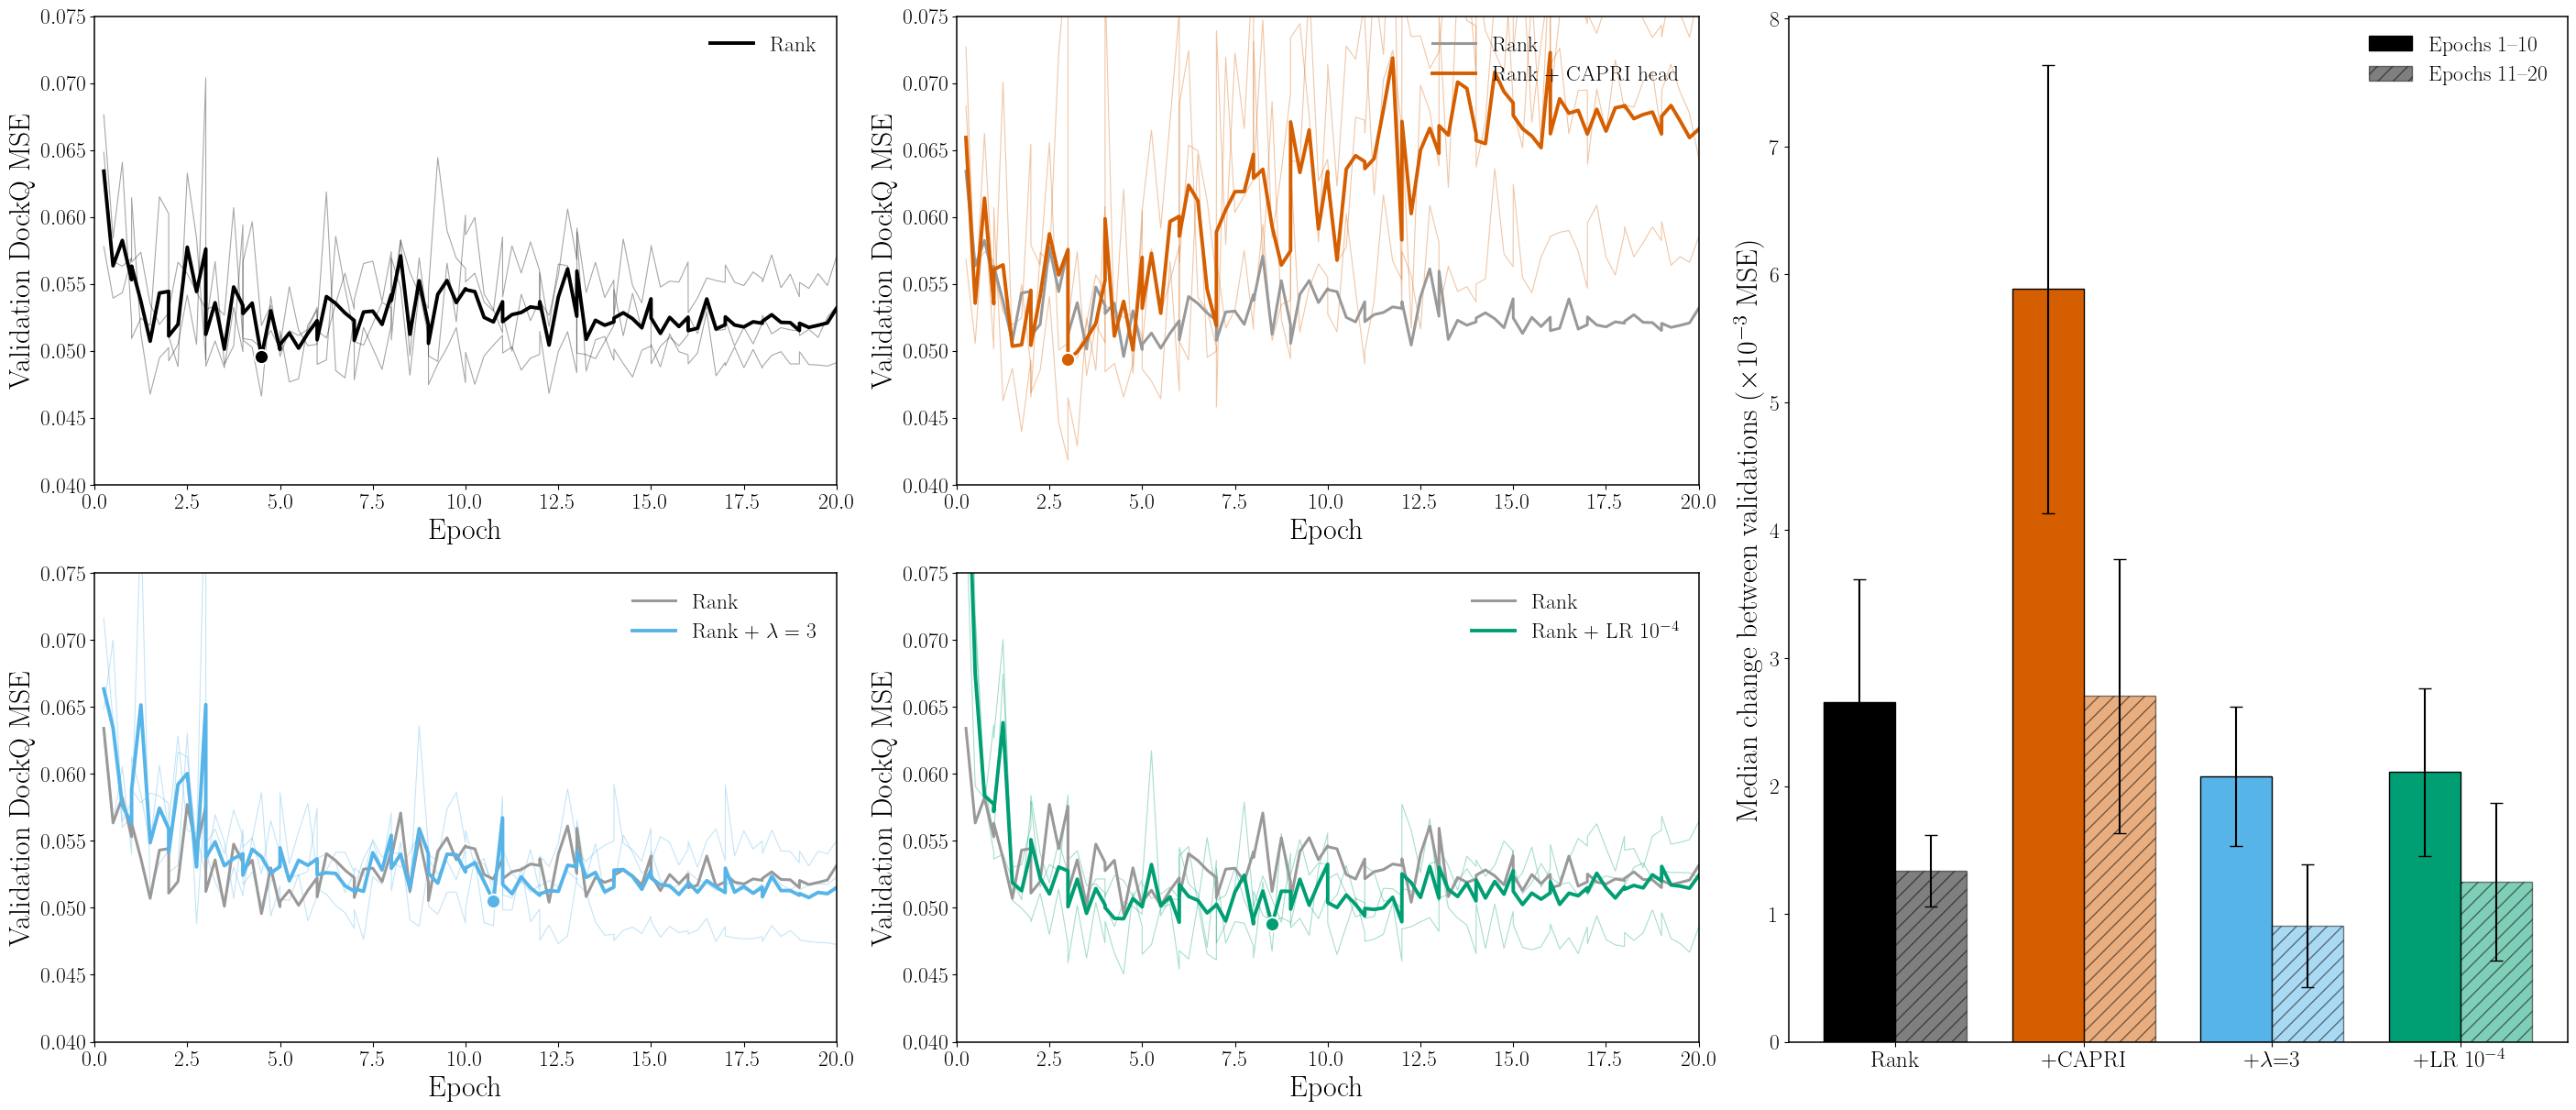

,early,late
config,,
rank,0.00266,0.00134
rank_capri,0.00589,0.00270
rank_lambda3,0.00207,0.00090
rank_lr1e-4,0.00211,0.00125


In [4]:
ref_curve = steps[steps.config == 'rank'].groupby('global_step').agg(x=('epoch_float', 'mean'), y=('val_target_mse', 'mean'))
fig = plt.figure(figsize=(28, 12), constrained_layout=True)
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.05])
axes = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(2)]
for ax, config in zip(axes, CONFIGS):
    for seed in SEEDS:
        r = steps[(steps.config == config) & (steps.seed == seed)].sort_values('global_step')
        ax.plot(r.epoch_float, r.val_target_mse, color=COLOR[config], lw=0.8, alpha=0.35)
    m = steps[steps.config == config].groupby('global_step').agg(x=('epoch_float', 'mean'), y=('val_target_mse', 'mean'))
    if config != 'rank':
        ax.plot(ref_curve.x, ref_curve.y, color='0.6', lw=2.2, label=LABEL['rank'])
    ax.plot(m.x, m.y, color=COLOR[config], lw=2.8, label=LABEL[config])
    i = m.y.idxmin(); ax.plot(m.x[i], m.y[i], 'o', ms=11, color=COLOR[config], mec='white', mew=1.5, zorder=5)
    ax.set(xlim=(0, EPOCHS), ylim=(0.04, 0.075)); ax.set_xlabel('Epoch'); ax.set_ylabel('Validation DockQ MSE')
    ax.legend(frameon=False, loc='upper right')
jumps = []
for (config, seed), s in steps.groupby(['config', 'seed']):
    s = s.sort_values('global_step'); d = s.val_target_mse.diff().abs()
    jumps.append(dict(config=config, seed=seed, early=d[s.epoch_float <= 10].median(), late=d[s.epoch_float > 10].median()))
jumps = pd.DataFrame(jumps); jumps.to_csv(EXPORT / 'validation_noise.csv', index=False)
axj = fig.add_subplot(gs[:, 2]); xj = np.arange(len(CONFIGS)); wj = .38
for k, (col, lab, hatch) in enumerate([('early', 'Epochs 1--10', None), ('late', 'Epochs 11--20', '//')]):
    v = jumps.groupby('config')[col].mean().loc[CONFIGS] * 1e3; e = jumps.groupby('config')[col].std().loc[CONFIGS] * 1e3
    axj.bar(xj + (k - .5) * wj, v, wj, yerr=e, capsize=5, color=[COLOR[c] for c in CONFIGS], hatch=hatch,
            alpha=1 if k == 0 else .5, edgecolor='black', label=lab)
axj.set_xticks(xj, [SHORT[c] for c in CONFIGS], fontsize=18)
axj.set_ylabel(r'Median change between validations ($\times10^{-3}$ MSE)')
axj.legend(frameon=False, loc='upper right')
save(fig, 'validation_curves_and_noise')
display(jumps.groupby('config')[['early', 'late']].mean().loc[CONFIGS].round(5))

## Test results

Left: DockQ MSE on validation (solid) and test (hatched) at the selected checkpoint; dashed lines mark each set's
constant-predictor MSE. Right: macro within-target Spearman $\langle\rho\rangle$, same layout. Seed values are
dots; error bars are seed SD.

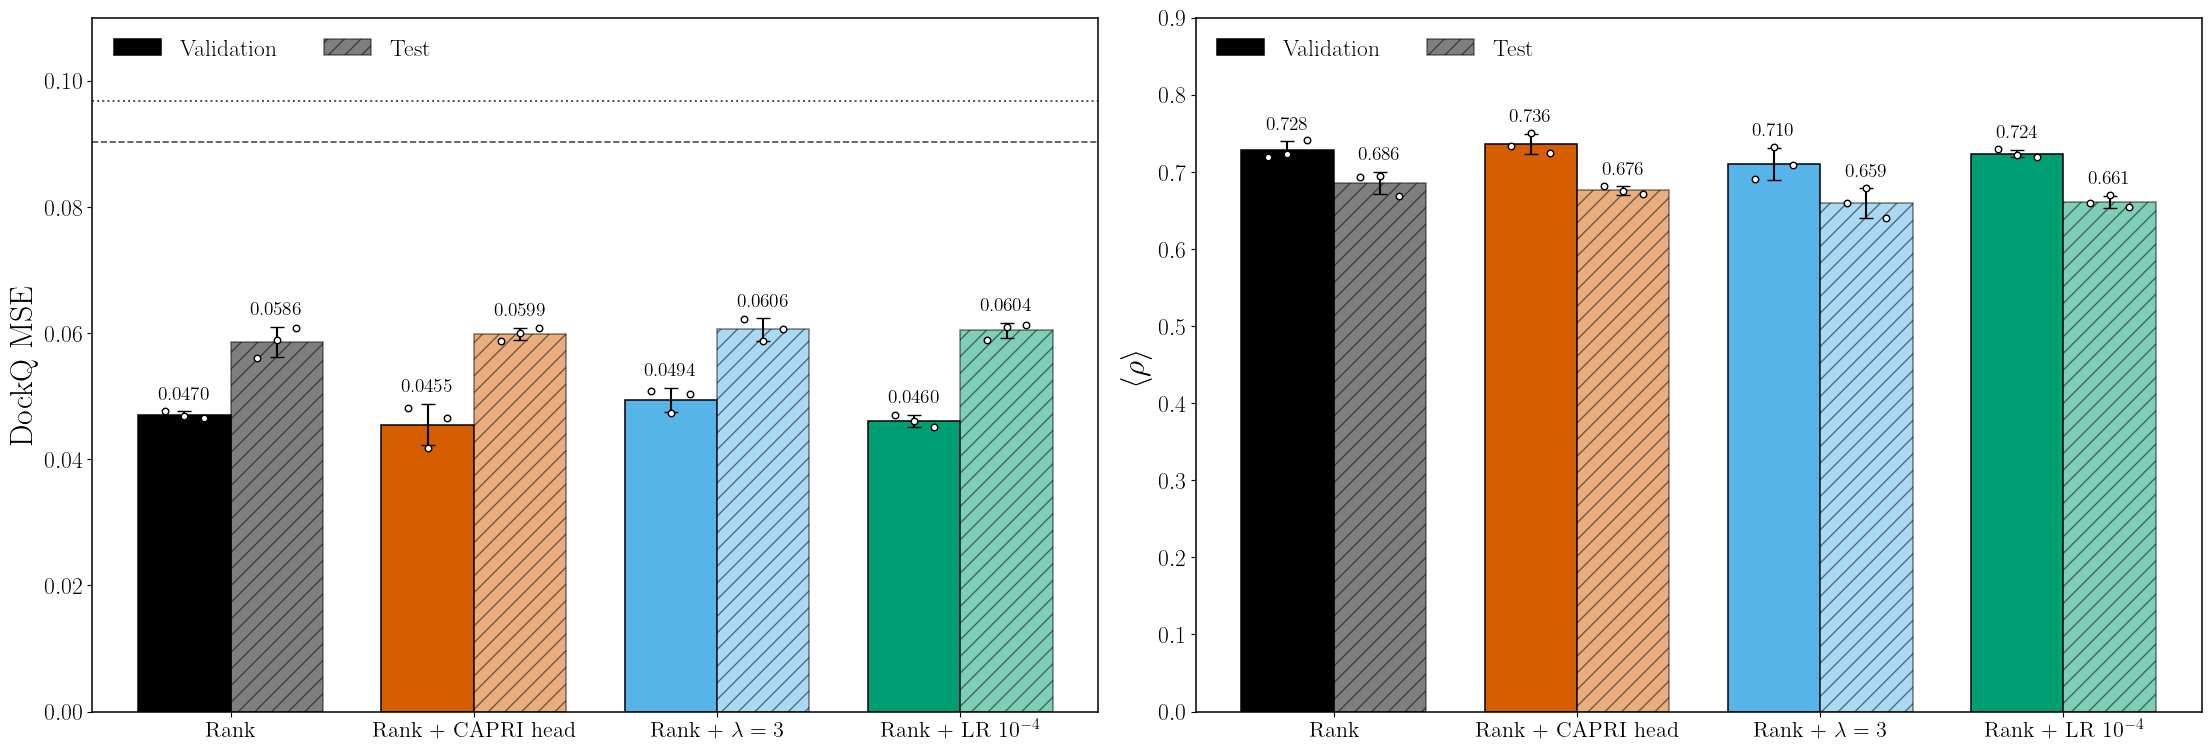

In [5]:
x = np.arange(len(CONFIGS)); w = .38
fig, axes = plt.subplots(1, 2, figsize=(22, 7.4), constrained_layout=True)
for ax, col, ylabel, fmt in [(axes[0], 'mse', 'DockQ MSE', '{:.4f}'), (axes[1], 'macro_rho', r'$\langle \rho \rangle$', '{:.3f}')]:
    for k, (split, hatch, alpha) in enumerate([('validation', None, 1), ('test', '//', .5)]):
        a = agg.loc[split].loc[CONFIGS]
        v, e = a[(col, 'mean')].to_numpy(), a[(col, 'std')].to_numpy()
        bars = ax.bar(x + (k - .5) * w, v, w, yerr=e, capsize=5, color=[COLOR[c] for c in CONFIGS], hatch=hatch,
                      alpha=alpha, edgecolor='black', lw=1.1, label=split.capitalize())
        ax.bar_label(bars, labels=[fmt.format(t) for t in v], padding=6, fontsize=14)
        for i, c in enumerate(CONFIGS):
            sv = metrics[(metrics.split == split) & (metrics.config == c)][col].to_numpy()
            ax.scatter(x[i] + (k - .5) * w + np.linspace(-.08, .08, 3), sv, s=22, zorder=6, facecolors='white', edgecolors='black')
    ax.set_xticks(x, [LABEL[c] for c in CONFIGS], fontsize=16); ax.set_ylabel(ylabel)
axes[0].axhline(REF['validation']['const_mse'], color='0.3', ls='--', lw=1.2)
axes[0].axhline(REF['test']['const_mse'], color='0.3', ls=':', lw=1.4)
axes[0].set_ylim(0, .11); axes[1].set_ylim(0, .9)
for ax in axes: ax.legend(frameon=False, loc='upper left', ncol=2)
save(fig, 'validation_vs_test')

### Did the validation ordering hold on test?

Each run's validation metric against its test metric. If the configurations that looked best on validation were
also best on test, points would line up along the diagonal direction. Paired test comparisons against the
reference (seed-averaged per test target, bootstrapped over the 29 test targets) are in the table below.

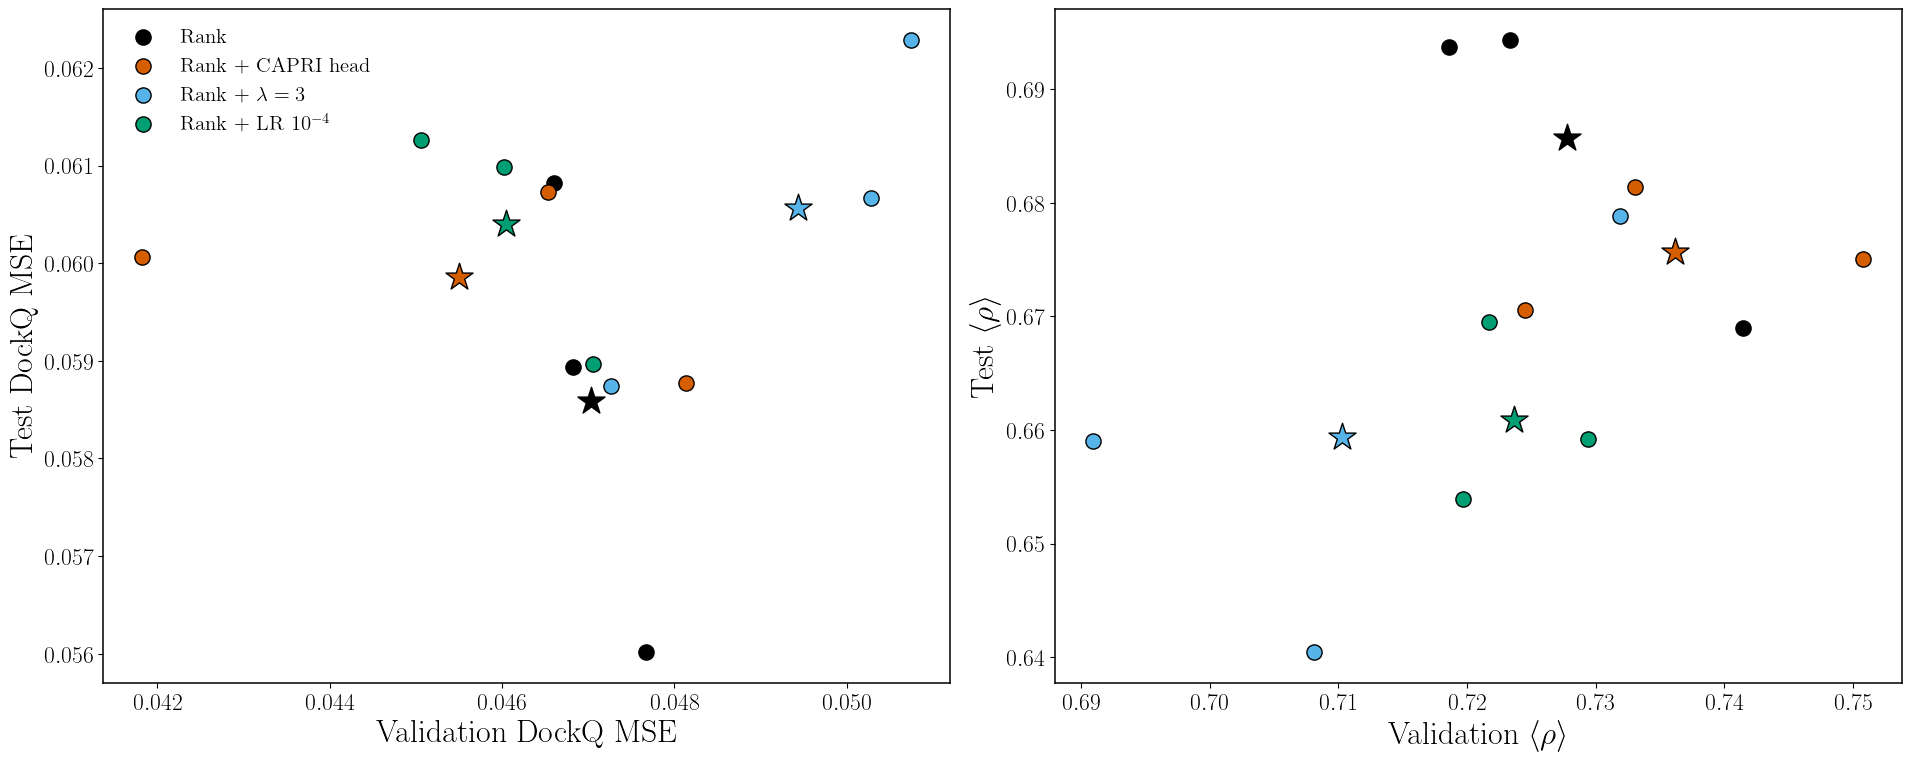

,config,metric,mean,lo,hi,wins,n
0,rank_capri,mse,-0.0013,-0.0050,0.0022,16,29
1,rank_capri,rho,-0.0100,-0.0306,0.0086,10,29
2,rank_capri,top1,0.0217,-0.0460,0.0925,17,29
3,rank_lambda3,mse,-0.0017,-0.0047,0.0011,10,29
4,rank_lambda3,rho,-0.0262,-0.0425,-0.0111,8,29
5,rank_lambda3,top1,-0.0403,-0.0961,0.0128,15,29
6,rank_lr1e-4,mse,-0.0022,-0.0053,0.0009,12,29
7,rank_lr1e-4,rho,-0.0248,-0.0426,-0.0078,7,29
8,rank_lr1e-4,top1,-0.0119,-0.0767,0.0522,18,29


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), constrained_layout=True)
piv = metrics.pivot_table(index=['config', 'seed'], columns='split', values=['mse', 'macro_rho'])
for ax, col, label in [(axes[0], 'mse', 'DockQ MSE'), (axes[1], 'macro_rho', r'$\langle \rho \rangle$')]:
    for config in CONFIGS:
        r = piv.loc[config, col]
        ax.scatter(r.validation, r.test, s=120, color=COLOR[config], edgecolors='black', label=LABEL[config], zorder=5)
        ax.scatter(r.validation.mean(), r.test.mean(), s=420, marker='*', color=COLOR[config], edgecolors='black', zorder=6)
    ax.set_xlabel(f'Validation {label}'); ax.set_ylabel(f'Test {label}')
axes[0].legend(frameon=False, loc='upper left', fontsize=15)
save(fig, 'validation_vs_test_per_run')

rng = np.random.default_rng(0)
tm = per_target[per_target.split == 'test'].groupby(['config', 'target_id'])[['mse', 'rho', 'top1']].mean()
eff = []
for config in CONFIGS[1:]:
    for metric, sign in [('mse', -1), ('rho', 1), ('top1', 1)]:
        d = sign * (tm.loc[config, metric] - tm.loc['rank', metric]).to_numpy()
        boots = rng.choice(d, size=(10_000, len(d))).mean(1)
        eff.append(dict(config=config, metric=metric, mean=d.mean(), lo=np.percentile(boots, 2.5), hi=np.percentile(boots, 97.5),
                        wins=int((d > 0).sum()), n=len(d)))
eff = pd.DataFrame(eff); eff.to_csv(EXPORT / 'test_paired_vs_rank.csv', index=False)
display(eff.round(4))

## Before and after on the test set

The same 29 test targets, scored by the feature-ladder models (old recipe: adaptive loss shares, dropout 0.1,
whole-graph pooling, best checkpoint chosen once per epoch) and by this experiment's reference configuration.
**Ladder, core** uses only amino-acid, chain and interface-flag inputs; **ladder, all features** uses the same
inputs as every run here. Each ladder model was evaluated at its own validation-selected checkpoint when it was
trained.

mse         macro_rho            top1          \
                          mean     std      mean     std    mean     std   
model                                                                      
Ladder, core            0.1070  0.0054    0.5526  0.0098  0.3193  0.0253   
Ladder, all features    0.0808  0.0097    0.6435  0.0289  0.4545  0.0739   
Rank (this experiment)  0.0586  0.0024    0.6857  0.0145  0.4471  0.0198   

                       high_bias          
                            mean     std  
model                                     
Ladder, core             -0.5380  0.0227  
Ladder, all features     -0.4006  0.0720  
Rank (this experiment)   -0.2976  0.0015

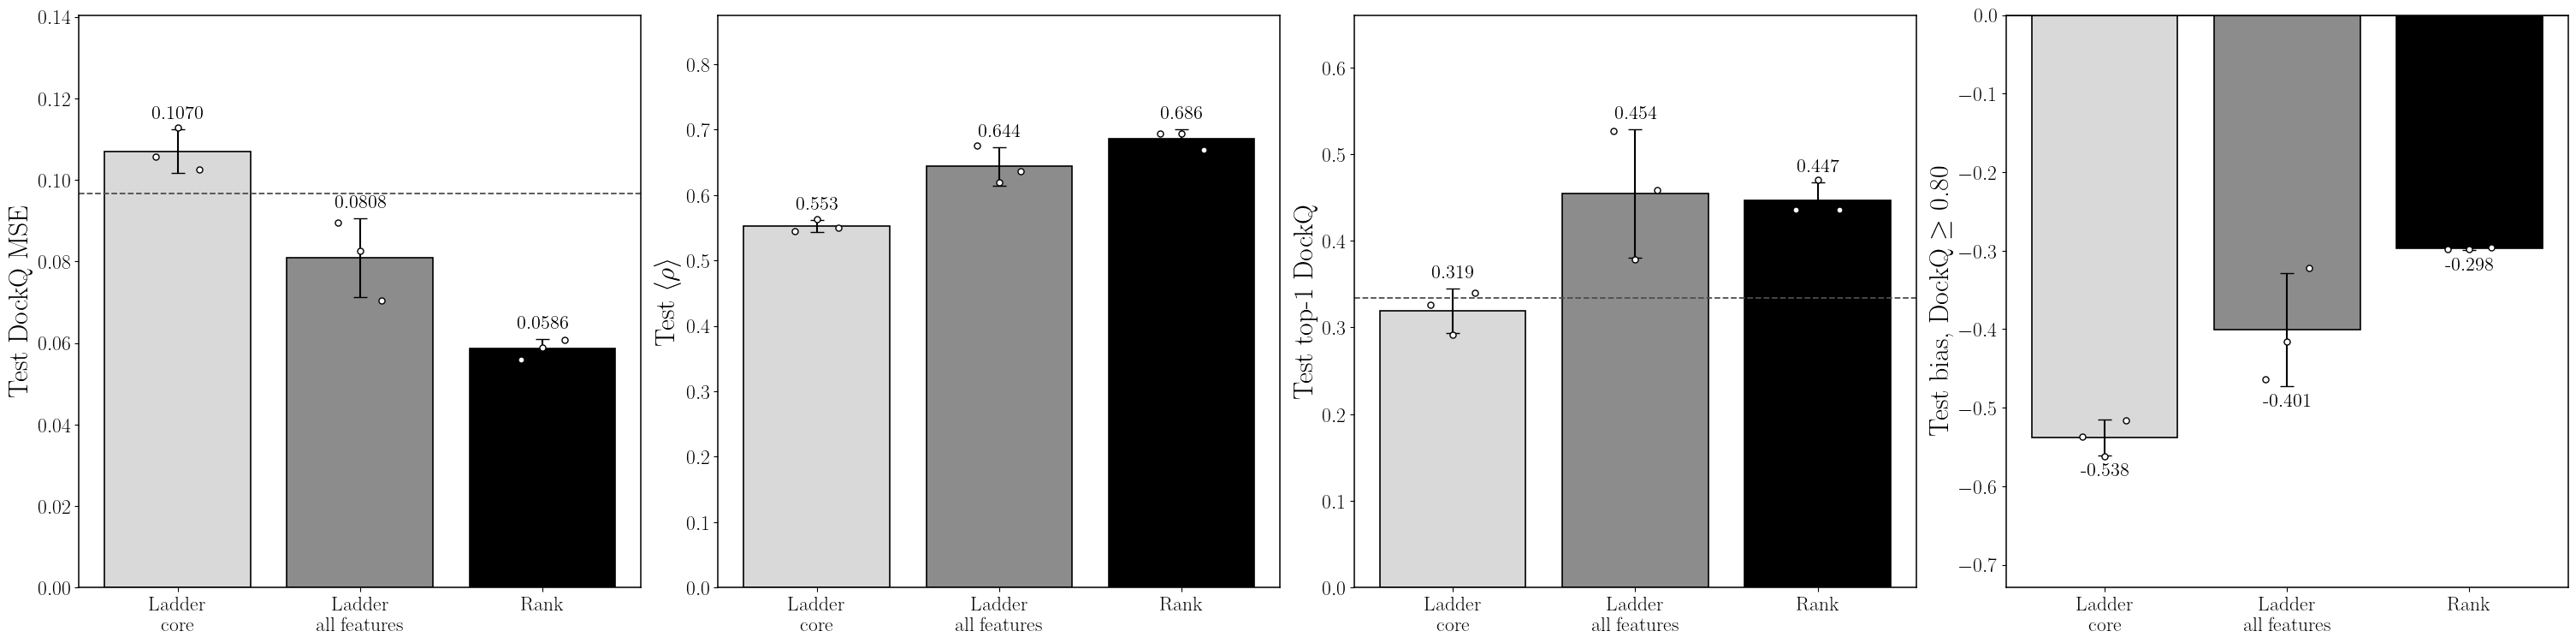

In [7]:
before_after = []
for name, preds in [('Ladder, core', {s: ladder_test['core', s] for s in SEEDS}),
                    ('Ladder, all features', {s: ladder_test['electrostatics', s] for s in SEEDS}),
                    ('Rank (this experiment)', {s: test_pred['rank', s] for s in SEEDS})]:
    for seed, p in preds.items():
        before_after.append(dict(model=name, seed=seed, **metrics_of(p)[0]))
before_after = pd.DataFrame(before_after); before_after.to_csv(EXPORT / 'test_before_after.csv', index=False)
ba = before_after.groupby('model', sort=False)[['mse', 'macro_rho', 'top1', 'high_bias']].agg(['mean', 'std'])
display(ba.round(4))

GRAYS = ['#d9d9d9', '#8c8c8c', '#000000']
panels = [('mse', 'Test DockQ MSE', '{:.4f}'), ('macro_rho', r'Test $\langle \rho \rangle$', '{:.3f}'),
          ('top1', 'Test top-1 DockQ', '{:.3f}'), ('high_bias', r'Test bias, DockQ $\geq$ 0.80', '{:.3f}')]
fig, axes = plt.subplots(1, 4, figsize=(30, 7.4), constrained_layout=True)
models = list(ba.index)
for ax, (col, ylabel, fmt) in zip(axes, panels):
    v, e = ba[(col, 'mean')].to_numpy(), ba[(col, 'std')].to_numpy()
    bars = ax.bar(np.arange(3), v, yerr=e, capsize=6, color=GRAYS, edgecolor='black', lw=1.2)
    ax.bar_label(bars, labels=[fmt.format(t) for t in v], padding=6, fontsize=16)
    for i, mname in enumerate(models):
        sv = before_after[before_after.model == mname][col].to_numpy()
        ax.scatter(i + np.linspace(-.12, .12, 3), sv, s=26, zorder=6, facecolors='white', edgecolors='black')
    ax.set_xticks(np.arange(3), ['Ladder\ncore', 'Ladder\nall features', 'Rank'], fontsize=17); ax.set_ylabel(ylabel)
    lo = min(0, (v - e).min() * 1.3); hi = max(0, (v + e).max() * 1.25)
    ax.set_ylim(lo, hi); ax.axhline(0, color='black', lw=.8)
axes[0].axhline(REF['test']['const_mse'], color='0.3', ls='--', lw=1.3)
axes[2].axhline(REF['test']['random_top1'], color='0.3', ls='--', lw=1.3)
save(fig, 'test_before_after')

### Per test target: all-features ladder vs rank

Seed-averaged within-target Spearman $\rho$ for each test target under the all-features ladder model and the rank
reference. Points above the diagonal are targets the new recipe ranks better.

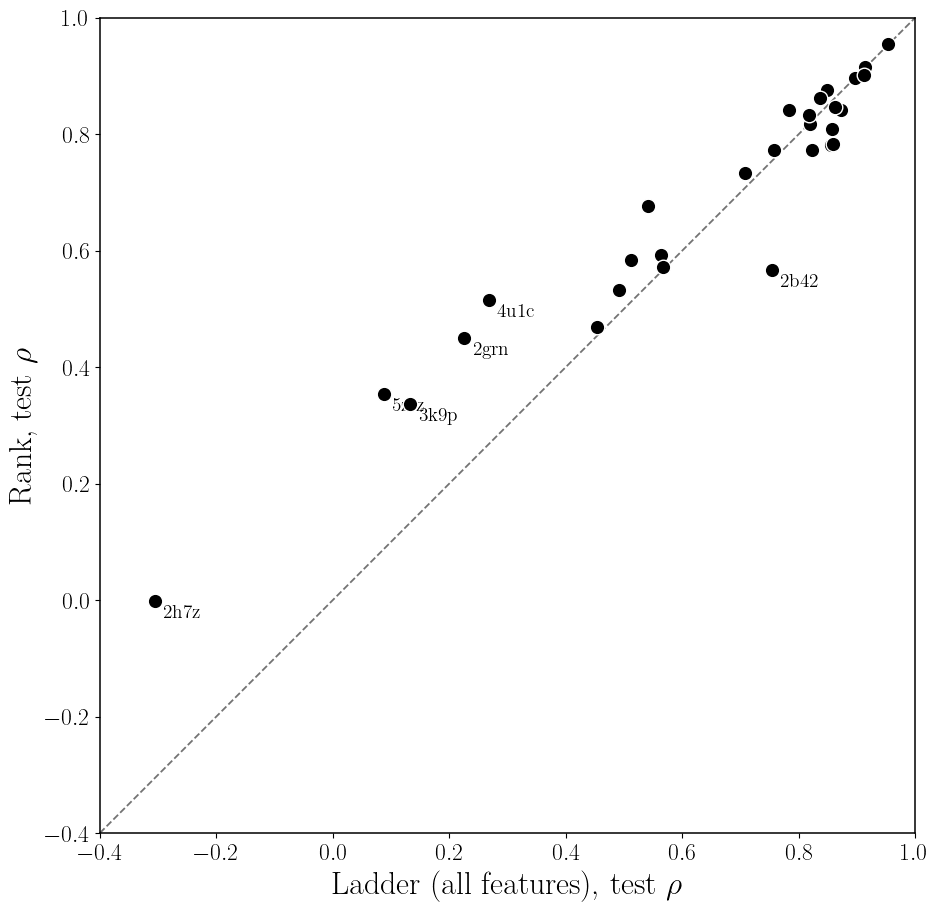

Rank better on 19/29 test targets; mean change +0.042.


In [8]:
def target_rho(preds):
    return pd.concat([p.groupby('target_id')[['true_target', 'predicted_target']].apply(
        lambda g: spearmanr(g.true_target, g.predicted_target).statistic) for p in preds], axis=1).mean(axis=1)
r_old = target_rho([ladder_test['electrostatics', s] for s in SEEDS]); r_new = target_rho([test_pred['rank', s] for s in SEEDS])
with mpl.rc_context({'axes.labelsize': 23}):
    fig, ax = plt.subplots(figsize=(9.5, 9), constrained_layout=True)
    ax.plot([-0.4, 1], [-0.4, 1], color='0.45', ls='--', lw=1.3)
    ax.scatter(r_old, r_new.loc[r_old.index], s=110, color='black', edgecolors='white', zorder=5)
    for t in r_old.index:
        if abs(r_new[t] - r_old[t]) > .15 or r_old[t] < .3:
            ax.annotate(t, (r_old[t], r_new[t]), textcoords='offset points', xytext=(6, -12), fontsize=14)
    ax.set(xlim=(-0.4, 1), ylim=(-0.4, 1)); ax.set_aspect('equal')
    ax.set_xlabel(r'Ladder (all features), test $\rho$'); ax.set_ylabel(r'Rank, test $\rho$')
    save(fig, 'test_per_target_rho_before_after')
print(f'Rank better on {(r_new > r_old).sum()}/{len(r_old)} test targets; mean change {(r_new - r_old).mean():+.3f}.')

## High-DockQ accuracy on test

Left: mean prediction error by true CAPRI class on test (seed mean), including the all-features ladder model for
reference. Middle: recall vs precision of high-quality decoys on validation (open) and test (filled), configuration
means. Right: for the CAPRI head, ROC AUC for identifying true highs on test using P(high) vs using the predicted
DockQ.

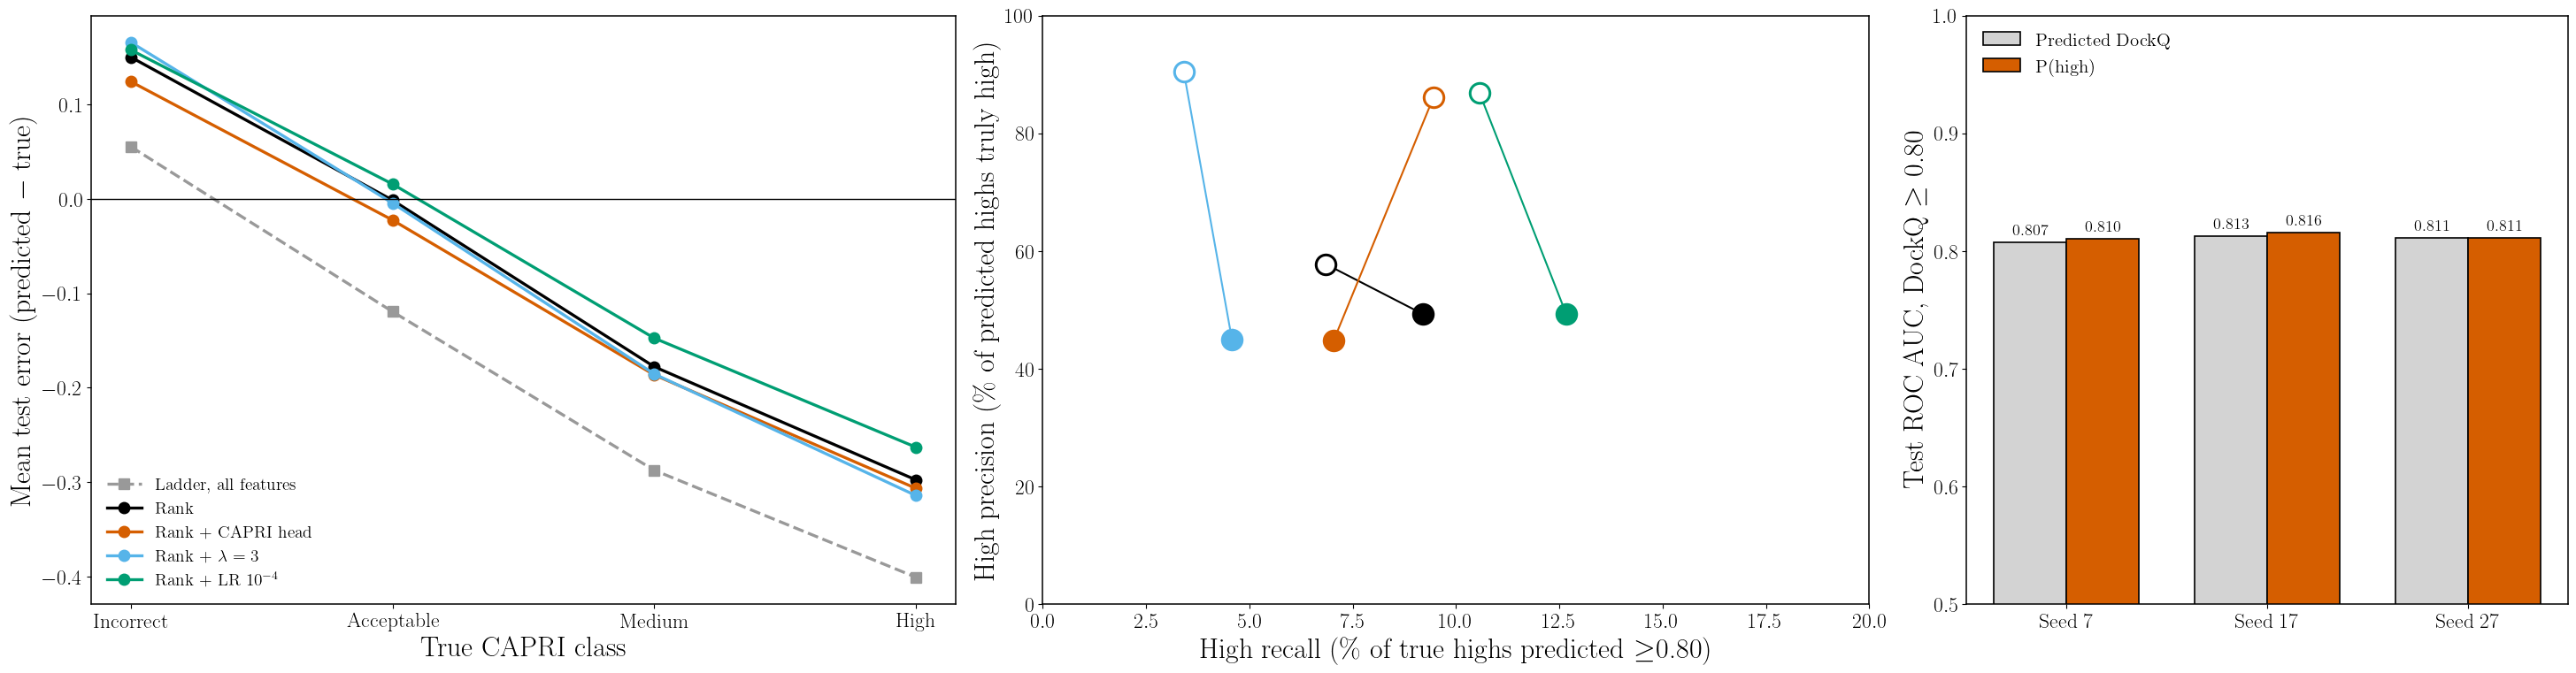

,high_recall,high_precision,n_pred_high,high_bias,low_bias,capri_acc,high_auc
config,,,,,,,
rank,0.092,0.492,812.667,-0.298,0.150,0.504,0.816
rank_capri,0.070,0.448,654.667,-0.307,0.124,0.533,0.810
rank_lambda3,0.046,0.450,442.000,-0.314,0.166,0.485,0.813
rank_lr1e-4,0.127,0.493,1134.667,-0.263,0.158,0.508,0.812


,scalar,p_high
seed,,
7,0.807,0.810
17,0.813,0.816
27,0.811,0.811


In [9]:
def class_bias(preds):
    rows = []
    for p in preds:
        cls = capri_of(p.true_target.to_numpy()); err = (p.predicted_target - p.true_target).to_numpy()
        rows.append([err[cls == k].mean() for k in range(4)])
    return np.mean(rows, axis=0)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(29, 7.5), gridspec_kw=dict(width_ratios=[1.15, 1.1, .8]),
                                 constrained_layout=True)
a1.plot(range(4), class_bias([ladder_test['electrostatics', s] for s in SEEDS]), color='0.6', ls='--', marker='s', ms=9,
        lw=2.4, label='Ladder, all features')
for config in CONFIGS:
    a1.plot(range(4), class_bias([test_pred[config, s] for s in SEEDS]), color=COLOR[config], marker='o', ms=9, lw=2.4,
            label=LABEL[config])
a1.axhline(0, color='black', lw=1); a1.set_xticks(range(4), [n.capitalize() for n in CAPRI_NAMES])
a1.set_xlabel('True CAPRI class'); a1.set_ylabel(r'Mean test error (predicted $-$ true)')
a1.legend(frameon=False, fontsize=14, loc='lower left')

for config in CONFIGS:
    for split, face in [('validation', 'white'), ('test', COLOR[config])]:
        r = metrics[(metrics.split == split) & (metrics.config == config)]
        a2.scatter(r.high_recall.mean() * 100, r.high_precision.mean() * 100, s=260, color=COLOR[config],
                   facecolors=face, edgecolors=COLOR[config], linewidths=2.2, zorder=5)
    rv = metrics[(metrics.split == 'validation') & (metrics.config == config)]
    rt = metrics[(metrics.split == 'test') & (metrics.config == config)]
    a2.annotate('', xy=(rt.high_recall.mean() * 100, rt.high_precision.mean() * 100),
                xytext=(rv.high_recall.mean() * 100, rv.high_precision.mean() * 100),
                arrowprops=dict(arrowstyle='->', color=COLOR[config], lw=1.5))
a2.set_xlabel(r'High recall (\% of true highs predicted $\geq$0.80)')
a2.set_ylabel(r'High precision (\% of predicted highs truly high)'); a2.set_xlim(0, 20); a2.set_ylim(0, 100)

auc_rows = []
for seed in SEEDS:
    p = test_pred['rank_capri', seed]; hi = p.true_target >= .8
    auc_rows.append(dict(seed=seed, scalar=roc_auc_score(hi, p.predicted_target), p_high=roc_auc_score(hi, p.p_high)))
auc = pd.DataFrame(auc_rows).set_index('seed')
xb = np.arange(3); wb = .36
for k, (col, lab, color) in enumerate([('scalar', 'Predicted DockQ', 'lightgray'), ('p_high', 'P(high)', COLOR['rank_capri'])]):
    bars = a3.bar(xb + (k - .5) * wb, auc[col], wb, color=color, edgecolor='black', lw=1.2, label=lab)
    a3.bar_label(bars, labels=[f'{v:.3f}' for v in auc[col]], padding=4, fontsize=13)
a3.set_xticks(xb, [f'Seed {s}' for s in SEEDS]); a3.set_ylim(.5, 1); a3.set_ylabel(r'Test ROC AUC, DockQ $\geq$ 0.80')
a3.legend(frameon=False, loc='upper left', fontsize=15)
save(fig, 'test_high_dockq')
display(metrics[metrics.split == 'test'].groupby('config')[['high_recall', 'high_precision', 'n_pred_high', 'high_bias',
                                                            'low_bias', 'capri_acc', 'high_auc']].mean().loc[CONFIGS].round(3))
display(auc.round(3))

## Observed vs predicted DockQ on the test set

Each panel pools the selected checkpoints of the three seeds of one configuration over all 29 test targets, plus the
all-features ladder model for reference. Shading is the log count of decoys; the dashed diagonal is perfect
agreement; dotted lines are CAPRI thresholds; the coloured line is the mean prediction in bins of observed DockQ.

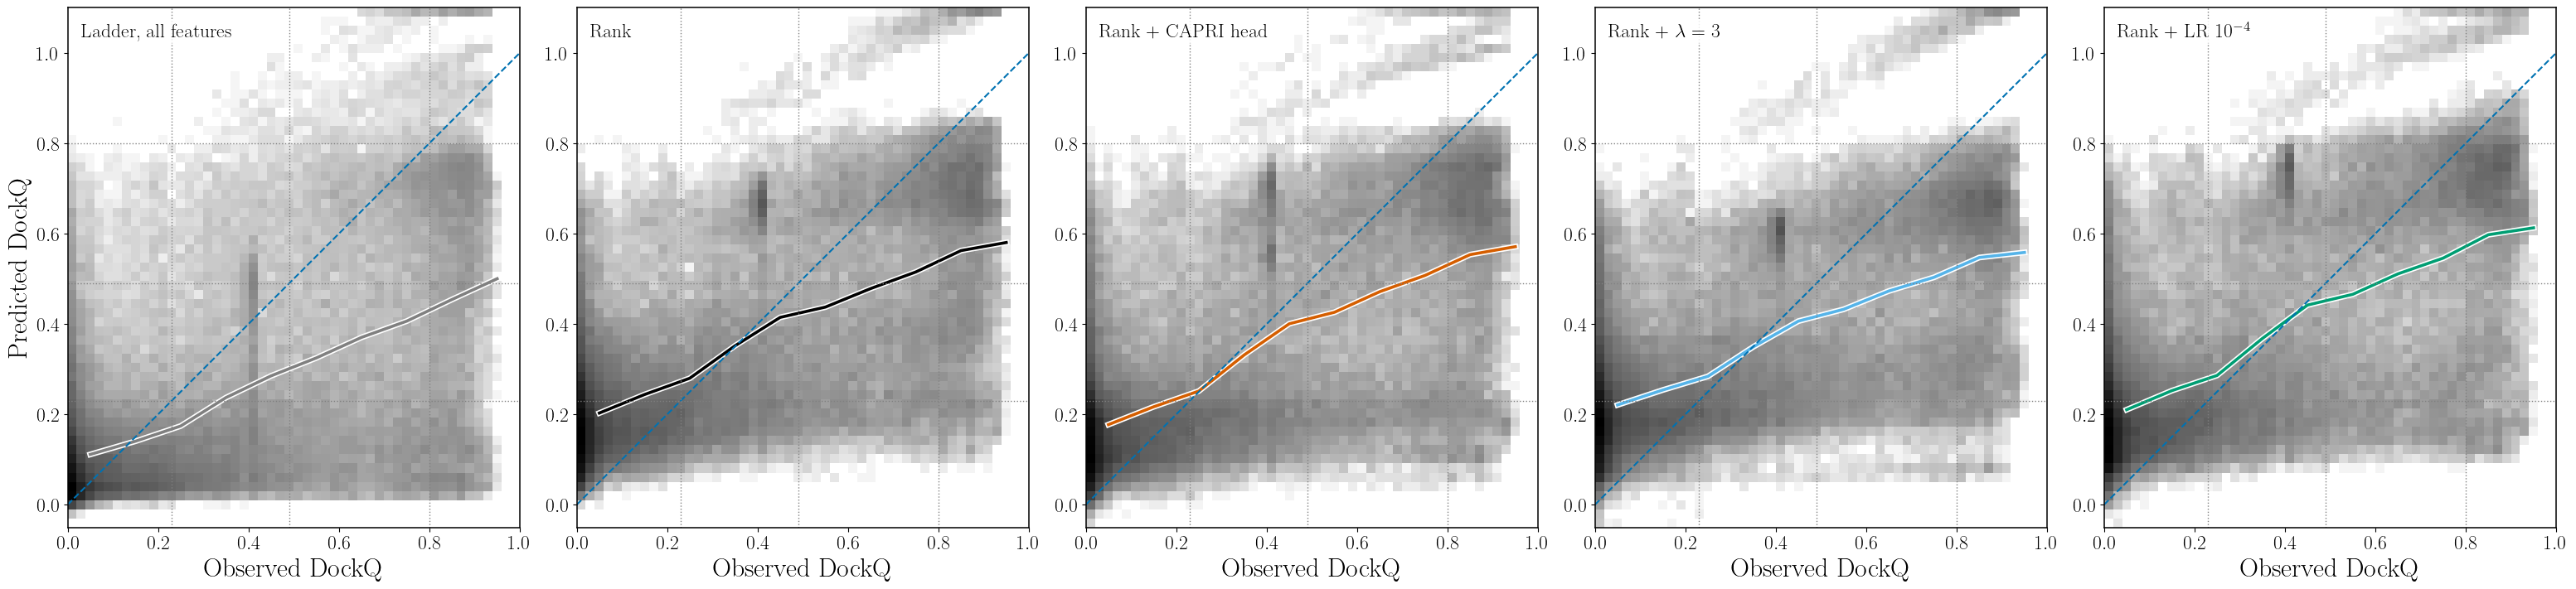

In [10]:
entries = [('Ladder, all features', [ladder_test['electrostatics', s] for s in SEEDS], '0.5')] + \
          [(LABEL[c], [test_pred[c, s] for s in SEEDS], COLOR[c]) for c in CONFIGS]
fig, axes = plt.subplots(1, 5, figsize=(31, 7), sharex=True, sharey=True, constrained_layout=True)
edges = np.linspace(0, 1, 11); mids = (edges[:-1] + edges[1:]) / 2
for ax, (name, preds, color) in zip(axes, entries):
    pr = pd.concat(preds)
    ax.hist2d(pr.true_target, pr.predicted_target.clip(-.05, 1.1), bins=[np.linspace(0, 1, 51), np.linspace(-.05, 1.1, 58)],
              cmap='Greys', norm=LogNorm(vmin=1), rasterized=True)
    means = pr.groupby(pd.cut(pr.true_target, edges, include_lowest=True), observed=False).predicted_target.mean()
    ax.plot(mids, means.to_numpy(), color='white', lw=5); ax.plot(mids, means.to_numpy(), color=color, lw=2.6)
    ax.plot([0, 1], [0, 1], color='#0072B2', ls='--', lw=1.5)
    for t in CAPRI:
        ax.axvline(t, color='0.5', ls=':', lw=1); ax.axhline(t, color='0.5', ls=':', lw=1)
    ax.text(.03, .97, name, transform=ax.transAxes, va='top', fontsize=17,
            bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=2))
    ax.set(xlim=(0, 1), ylim=(-.05, 1.1)); ax.set_aspect('equal', adjustable='box'); ax.set_xlabel('Observed DockQ')
    ax.tick_params(labelleft=True)
axes[0].set_ylabel('Predicted DockQ')
save(fig, 'test_observed_vs_predicted')

### Every test target: rank reference, seed 17

All 29 test targets for the rank reference (seed 17), at its selected checkpoint. Each translucent black circle is
one decoy; shared axes; the dashed line is perfect agreement; the annotation gives the target and its
within-target Spearman $\rho$.

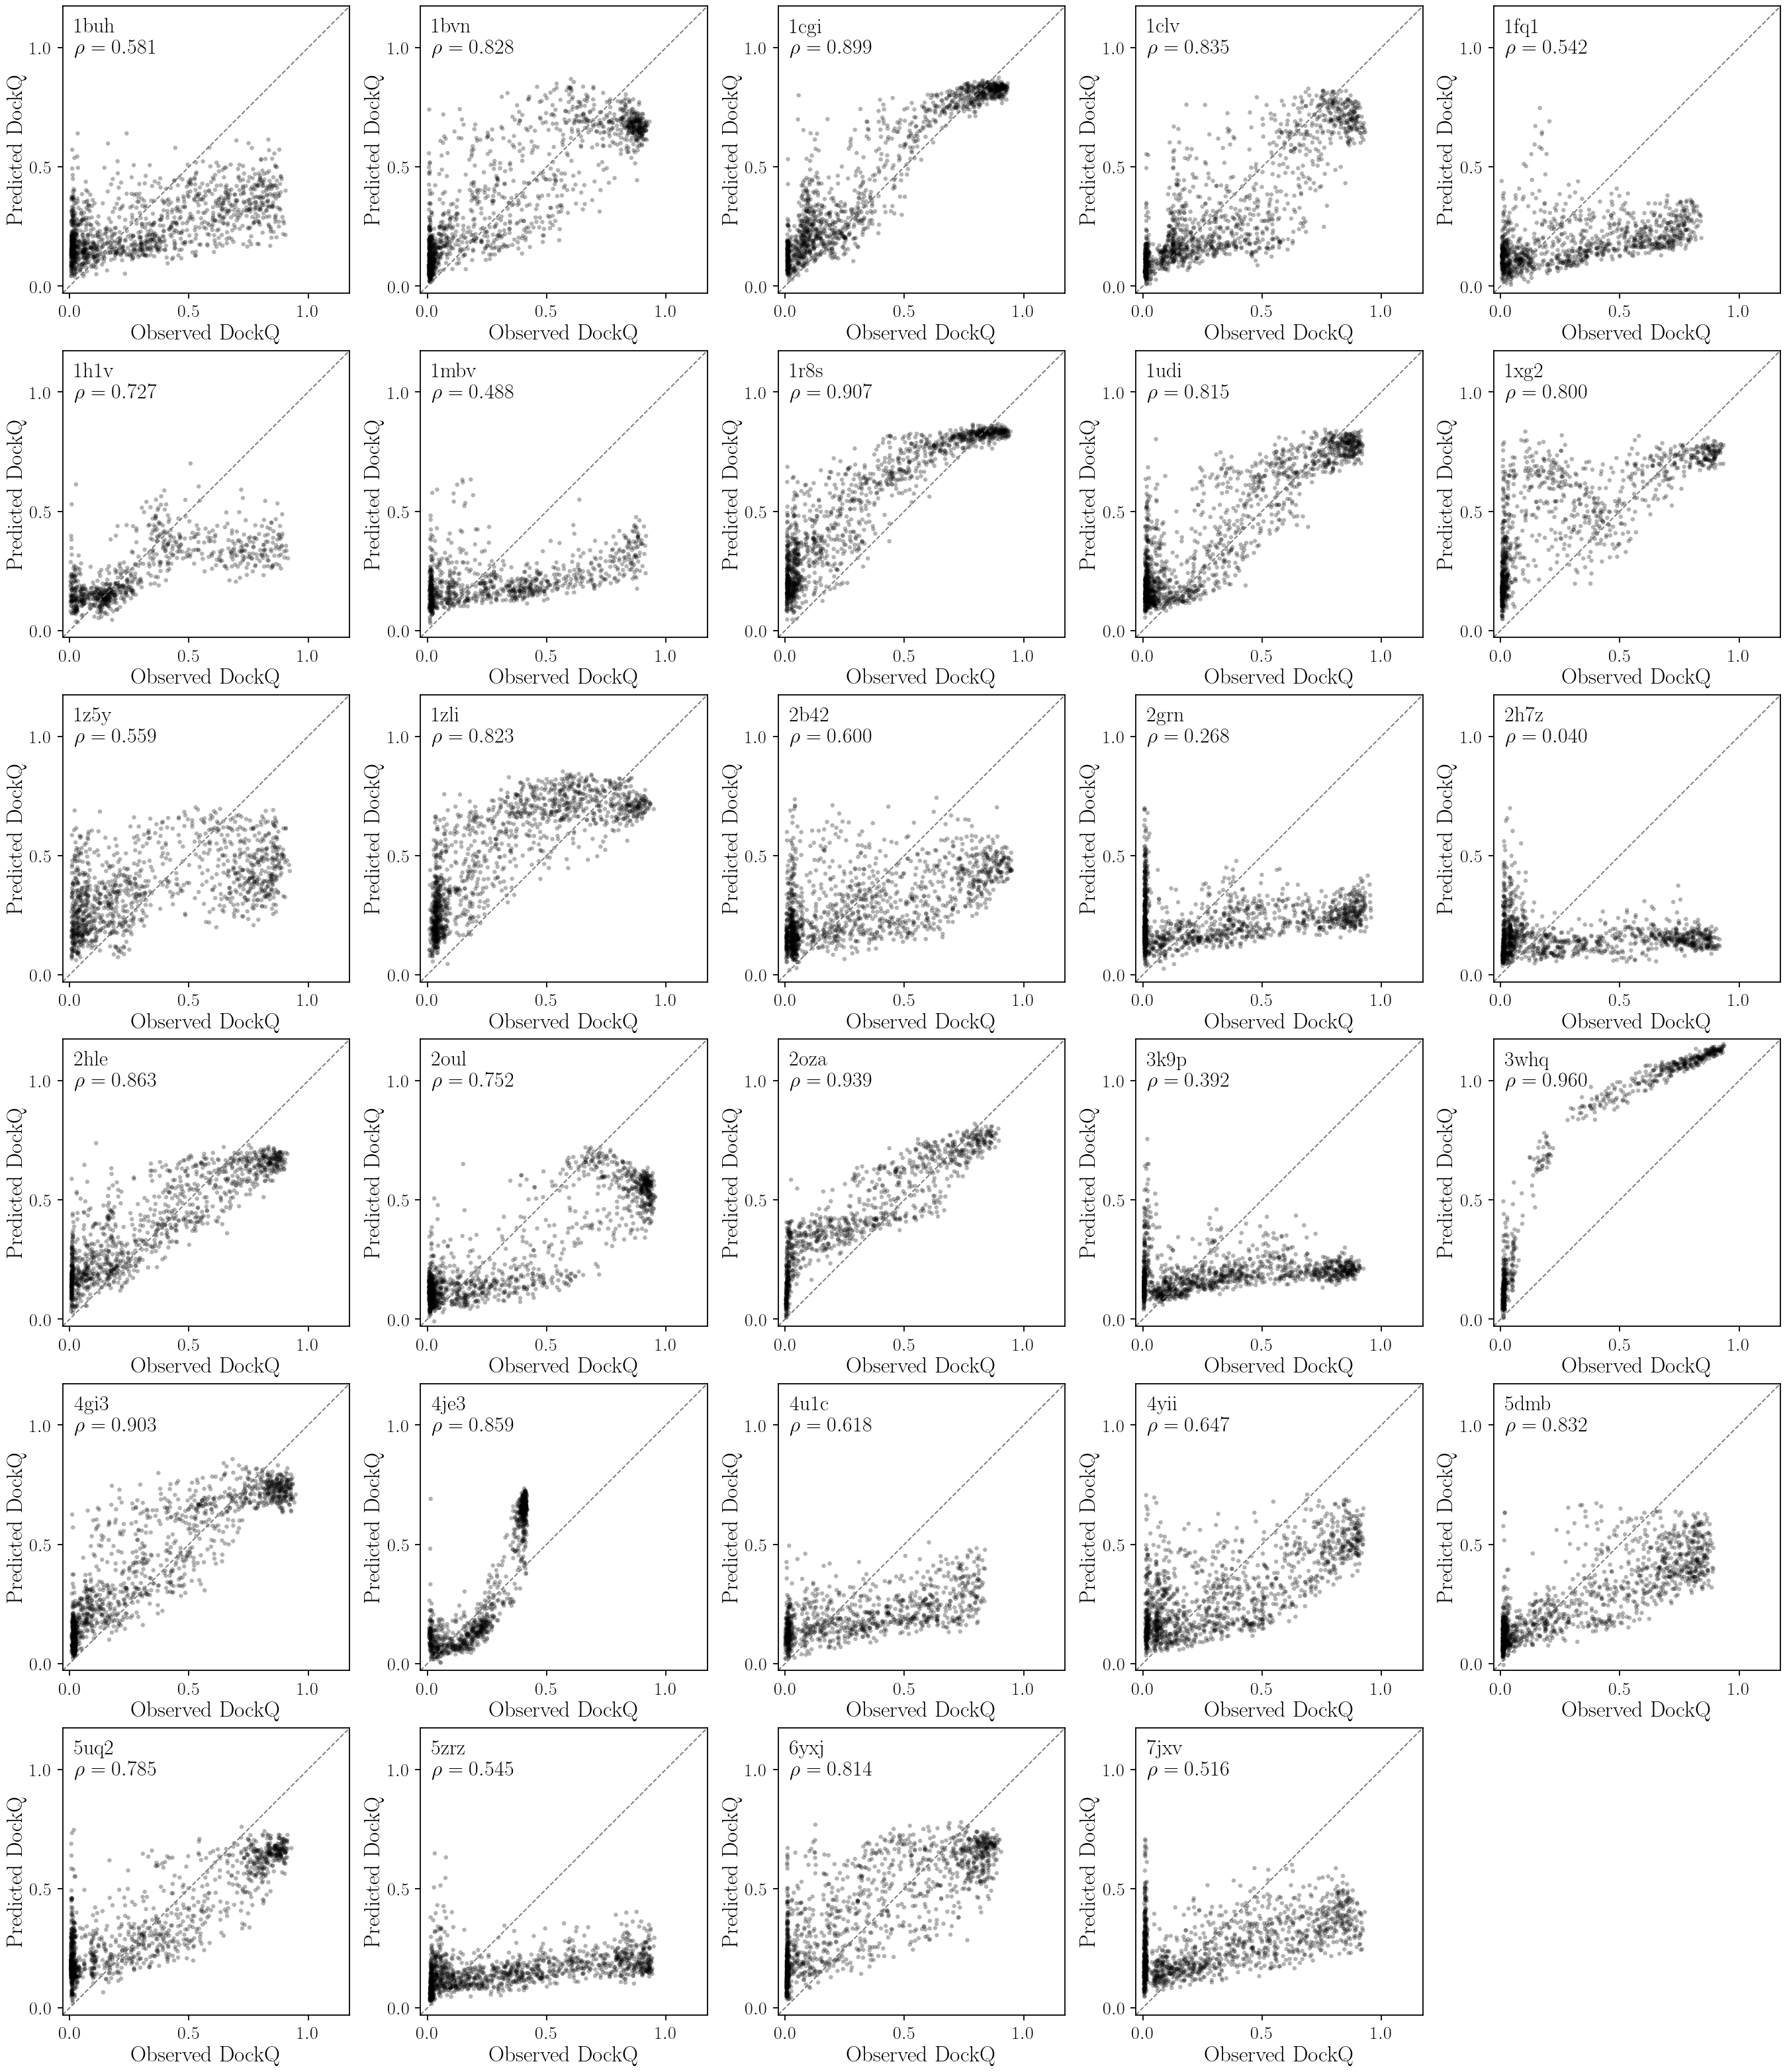

In [11]:
PANEL_SEED = 17
sel = test_pred['rank', PANEL_SEED]
tgts = sorted(sel.target_id.unique()); ncols = 5; nrows = int(np.ceil(len(tgts) / ncols))
axis_low = min(0.0, sel.true_target.min(), sel.predicted_target.min()) - 0.02
axis_high = max(1.0, sel.true_target.max(), sel.predicted_target.max()) + 0.02
with mpl.rc_context({'axes.labelsize': 24, 'xtick.labelsize': 20, 'ytick.labelsize': 20}):
    fig, axes = plt.subplots(nrows, ncols, figsize=(27, 5.2 * nrows), sharex=True, sharey=True, constrained_layout=True)
    for ax, target in zip(axes.flat, tgts):
        g = sel[sel.target_id == target]
        rho = spearmanr(g.true_target, g.predicted_target).statistic
        ax.scatter(g.true_target, g.predicted_target, color='black', alpha=0.30, s=22, edgecolors='none', rasterized=True)
        ax.plot([axis_low, axis_high], [axis_low, axis_high], color='0.45', ls='--', lw=1.3)
        ax.text(0.04, 0.96, target + '\n' + rf'$\rho = {rho:.3f}$', transform=ax.transAxes, ha='left', va='top', fontsize=23,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
        ax.set(xlim=(axis_low, axis_high), ylim=(axis_low, axis_high), xlabel='Observed DockQ', ylabel='Predicted DockQ')
        ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1]); ax.set_aspect('equal', adjustable='box')
        ax.tick_params(labelbottom=True, labelleft=True, length=6, width=1.3, pad=6)
        for spine in ax.spines.values():
            spine.set_linewidth(1.3)
    for ax in list(axes.flat)[len(tgts):]:
        ax.set_visible(False)
    save(fig, f'test_per_target_rank_seed{PANEL_SEED}')

### Every test target: rank + CAPRI head, best validation seed

The same figure for the rank + CAPRI head configuration, using its seed with the lowest **validation** DockQ MSE
(chosen on validation, not test, so the panel is not flattered by test-set selection). Each translucent circle is
one decoy at that run's selected checkpoint; shared axes; the dashed line is perfect agreement; the annotation gives
the target and its within-target Spearman $\rho$.

Rank + CAPRI head: validation MSE by seed {7: 0.0481, 17: 0.0418, 27: 0.0465}; best = seed 17 (test MSE 0.0601).


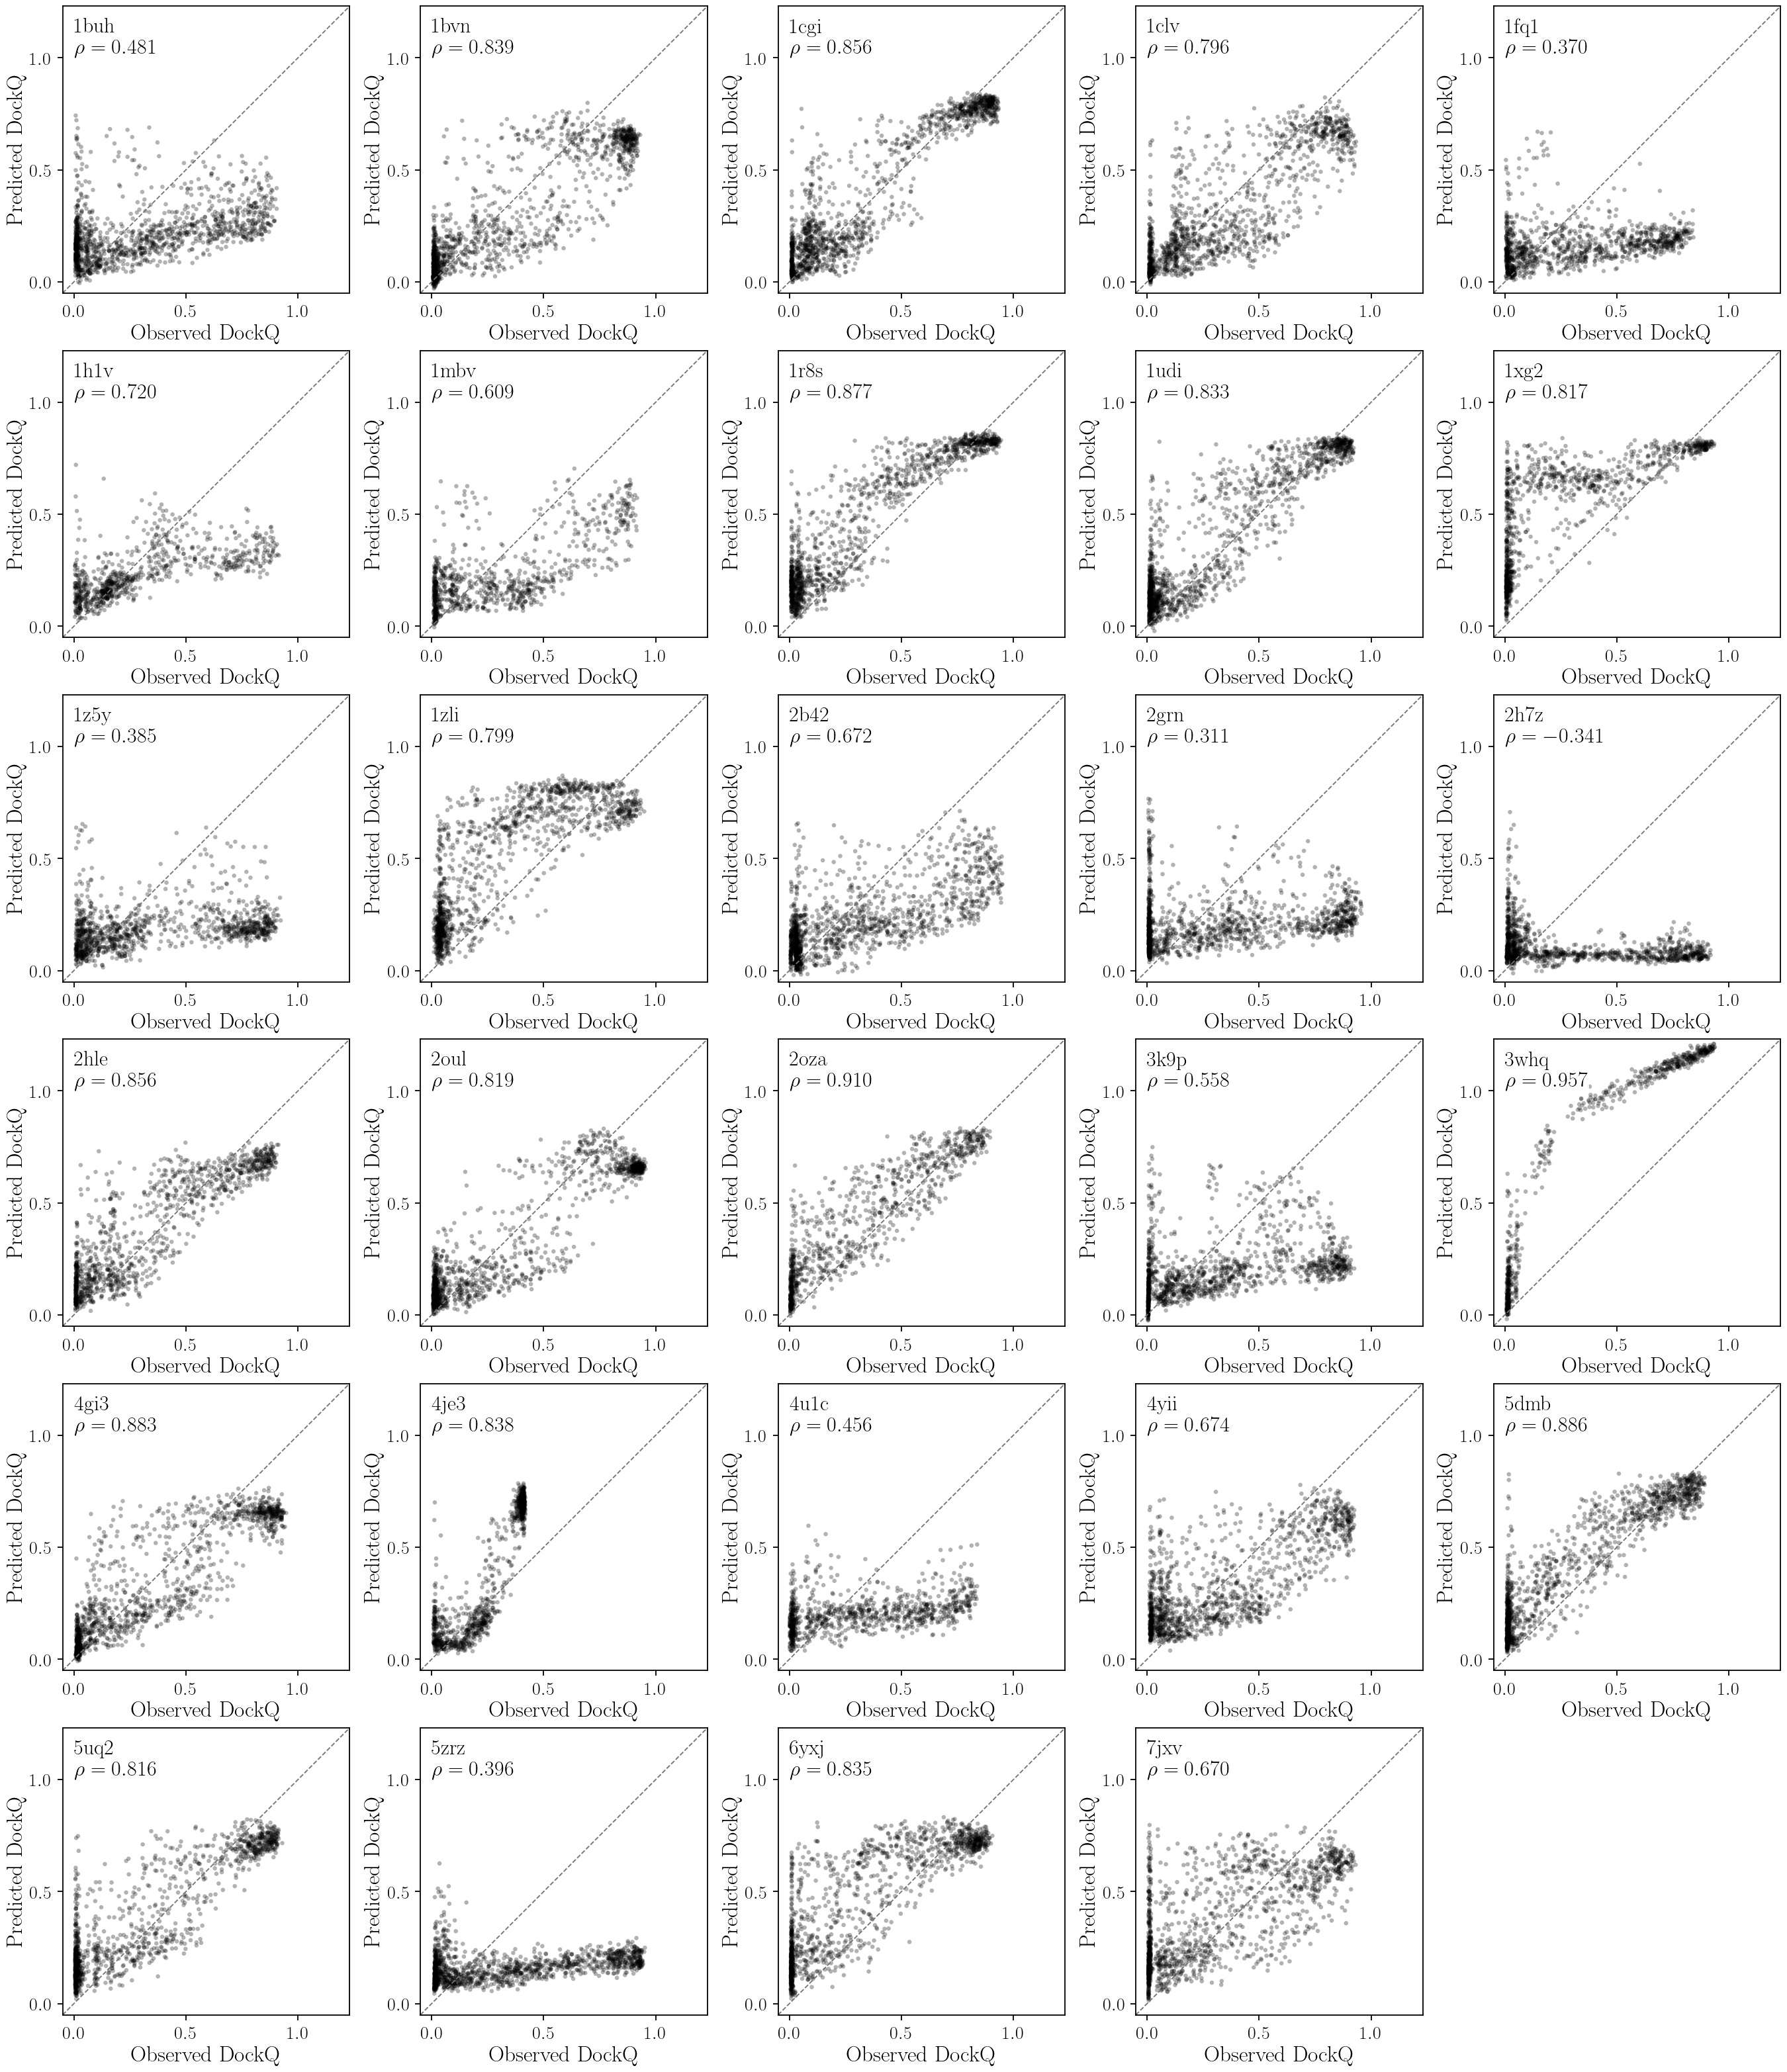

In [12]:
val_mse = metrics[(metrics.split == 'validation') & (metrics.config == 'rank_capri')].set_index('seed').mse
CAPRI_SEED = int(val_mse.idxmin())
print(f'Rank + CAPRI head: validation MSE by seed {val_mse.round(4).to_dict()}; best = seed {CAPRI_SEED} '
      f'(test MSE {metrics[(metrics.split == "test") & (metrics.config == "rank_capri") & (metrics.seed == CAPRI_SEED)].mse.iloc[0]:.4f}).')
sel = test_pred['rank_capri', CAPRI_SEED]
tgts = sorted(sel.target_id.unique()); ncols = 5; nrows = int(np.ceil(len(tgts) / ncols))
axis_low = min(0.0, sel.true_target.min(), sel.predicted_target.min()) - 0.02
axis_high = max(1.0, sel.true_target.max(), sel.predicted_target.max()) + 0.02
with mpl.rc_context({'axes.labelsize': 24, 'xtick.labelsize': 20, 'ytick.labelsize': 20}):
    fig, axes = plt.subplots(nrows, ncols, figsize=(27, 5.2 * nrows), sharex=True, sharey=True, constrained_layout=True)
    for ax, target in zip(axes.flat, tgts):
        g = sel[sel.target_id == target]
        rho = spearmanr(g.true_target, g.predicted_target).statistic
        ax.scatter(g.true_target, g.predicted_target, color='black', alpha=0.30, s=22, edgecolors='none', rasterized=True)
        ax.plot([axis_low, axis_high], [axis_low, axis_high], color='0.45', ls='--', lw=1.3)
        ax.text(0.04, 0.96, target + '\n' + rf'$\rho = {rho:.3f}$', transform=ax.transAxes, ha='left', va='top', fontsize=23,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
        ax.set(xlim=(axis_low, axis_high), ylim=(axis_low, axis_high), xlabel='Observed DockQ', ylabel='Predicted DockQ')
        ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1]); ax.set_aspect('equal', adjustable='box')
        ax.tick_params(labelbottom=True, labelleft=True, length=6, width=1.3, pad=6)
        for spine in ax.spines.values():
            spine.set_linewidth(1.3)
    for ax in list(axes.flat)[len(tgts):]:
        ax.set_visible(False)
    save(fig, f'test_per_target_rank_capri_seed{CAPRI_SEED}')

## Reconstruction on the test set

Structural reconstruction of the selected checkpoints on the test targets (from `reconstruction_summary.csv`),
alongside the all-features ladder models. These checkpoints are chosen for DockQ, so reconstruction reflects how
far the autoencoder had trained by then.

aa_identity_accuracy_pct        interface_node_accuracy_pct  \
                                 mean    std                        mean   
config                                                                     
ladder                         86.879  4.364                      98.134   
rank                           36.083  6.134                      96.999   
rank_capri                     26.058  2.565                      97.065   
rank_lambda3                   41.820  6.348                      97.198   
rank_lr1e-4                    27.965  4.226                      97.186   

                    edge_f1_pct        ca_dist_mae_angstrom         
                std        mean    std                 mean    std  
config                                                              
ladder        0.542      78.468  4.135                1.216  0.128  
rank          0.145      72.123  1.894                0.748  0.016  
rank_capri    0.151      63.011  3.636                0.922  0.071  
rank_lambda3  0.183      73.444  4.119                0.716  0.029  
rank_lr1e-4   0.127      61.070  5.764                0.905  0.056

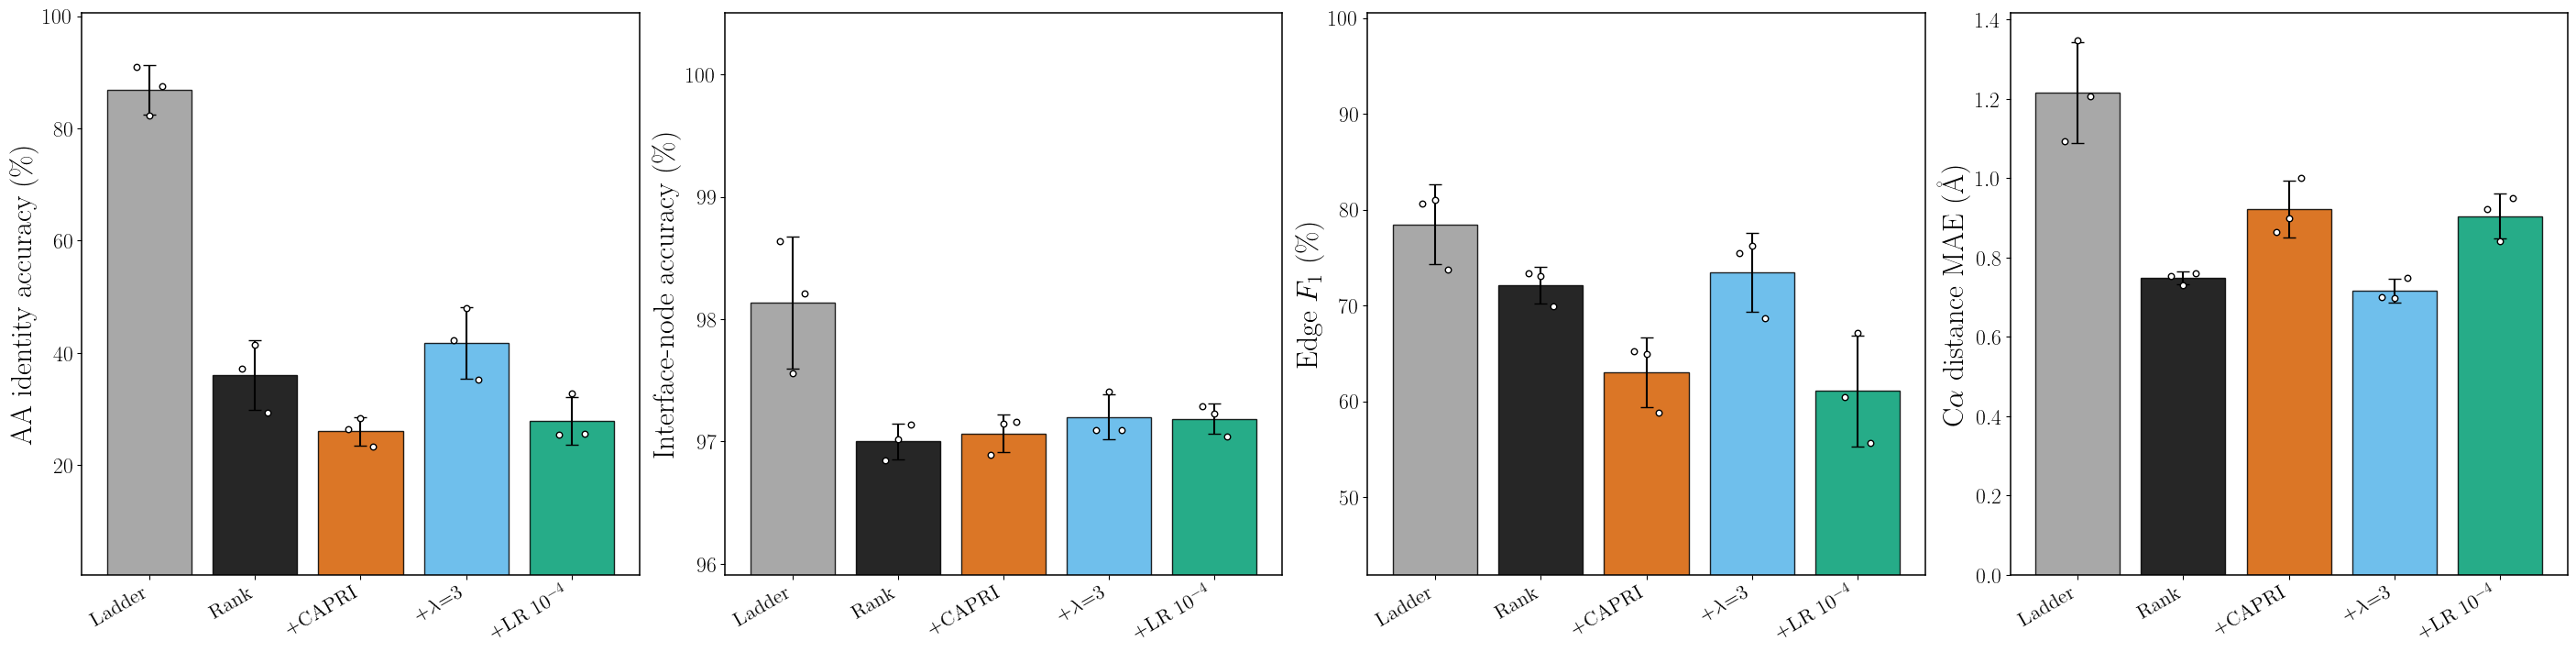

In [13]:
ladder_recon = pd.concat([pd.read_csv(LADDER / f'gat4_residual_electrostatics_seed{s}' / 'reconstruction_summary.csv').assign(seed=s)
                          for s in SEEDS]).assign(config='ladder')
rc = pd.concat([recon, ladder_recon], ignore_index=True)
RC = ['aa_identity_accuracy_pct', 'interface_node_accuracy_pct', 'edge_f1_pct', 'ca_dist_mae_angstrom']
RC_LABEL = {'aa_identity_accuracy_pct': r'AA identity accuracy (\%)', 'interface_node_accuracy_pct': r'Interface-node accuracy (\%)',
            'edge_f1_pct': r'Edge $F_1$ (\%)', 'ca_dist_mae_angstrom': r'C$\alpha$ distance MAE (\AA)'}
order = ['ladder'] + CONFIGS
rcm = rc.groupby('config')[RC].agg(['mean', 'std']).loc[order]
display(rcm.round(3)); rcm.to_csv(EXPORT / 'test_reconstruction.csv')
fig, axes = plt.subplots(1, 4, figsize=(28, 7), constrained_layout=True)
colors = ['0.6'] + [COLOR[c] for c in CONFIGS]
for ax, col in zip(axes, RC):
    v, e = rcm[(col, 'mean')].to_numpy(), rcm[(col, 'std')].to_numpy()
    ax.bar(np.arange(len(order)), v, yerr=e, capsize=5, color=colors, edgecolor='black', alpha=.85)
    for i, c in enumerate(order):
        sv = rc[rc.config == c][col].to_numpy()
        ax.scatter(i + np.linspace(-.12, .12, len(sv)), sv, s=22, zorder=6, facecolors='white', edgecolors='black')
    ax.set_xticks(np.arange(len(order)), ['Ladder'] + [SHORT[c] for c in CONFIGS], rotation=30, ha='right', fontsize=16)
    ax.set_ylabel(RC_LABEL[col])
    if 'pct' in col:
        lo = (v - e).min(); ax.set_ylim(max(0, lo - .3 * (100 - lo)), 100.5)
save(fig, 'test_reconstruction')

## Comparison with other scoring functions

How does the rank model compare with the scoring functions benchmarked in Chapter 3 (ZRank2, ITScorePP, Rosetta,
PyDock, VoroMQA, Deeprank-GNN-ESM) and with VoroIF-GNN? For each validation and test target, every method's
Spearman $\rho$ between its score and DockQ is computed on **exactly the same decoys** the rank model scored, so
differences come from the methods, not the decoy sets.

- **Sources.** Main-dataset targets: the manuscript's balanced per-decoy tables (our decoys are a subset of them,
  82--99\% of each table). Those tables repeat some decoys to balance the classes (supersampling); here each decoy
  counts once, so every method is scored on the same set of distinct decoys as the rank model. BM5.5 targets: the raw `bm_55_scoring` files (sampled and random-negative sets), parsed
  with the parsers in `ch3_comparison/raw_score_parsers.py`, which were previously validated byte-for-byte against
  the manuscript's tables. VoroIF-GNN: `sum_of_gnn_scores` from `/scratch/voroif_gnn/results/balanced`.
- **Sign convention (as in the manuscript).** $\rho$ is oriented so that **more negative is better**: energy-like
  scores (ZRank2, ITScorePP, Rosetta, PyDock) are used as is, and higher-is-better scores (VoroMQA,
  Deeprank-GNN-ESM, VoroIF-GNN, the rank model's predicted DockQ) are negated.
- **Exclusions.** GNN-DOVE is omitted, as in the manuscript. Deeprank-GNN-ESM is excluded on BM5.5 targets (it was
  trained on 60 of the 62) and on 2OUL and 1AY7 (manuscript exclusions). VoroIF-GNN was only run on main-dataset
  targets. Targets whose scored decoys are not the ones in our graphs (Rosetta-relaxed decoys with different names)
  are dropped for every method.
- **Rank model.** Per target, the mean of the three seeds' $\rho$ at their selected checkpoints. Its validation
  targets informed model selection, so **test-only numbers are the clean comparison**; validation + test is shown
  for a larger sample.

In [14]:
import sys
sys.path.insert(0, str(GATE / 'ch3_comparison'))
from raw_score_parsers import PARSERS, parse_dockq, parse_deeprank_csv, base_key

SCORE_ROOT = Path('/scratch/ppi_scoring_data')
BALANCED = Path('/scratch/uniformly_sampled_ppi_data/all_supersampled_balanced_datasets 3/all_supersampled_balanced_datasets')
VOROIF = Path('/scratch/voroif_gnn/results/balanced')
MANUSCRIPT_RHO = Path('/scratch/uniformly_sampled_ppi_data/supersampled_correlation_dataset_final_manuscript.csv')
CLASSICAL = ['ZRank2', 'ITScorePP', 'Rosetta', 'PyDock', 'VoroMQA']
METHODS = CLASSICAL + ['Deeprank-GNN-ESM', 'VoroIF-GNN', 'GATE']
HIGHER_BETTER = {'ZRank2': False, 'ITScorePP': False, 'Rosetta': False, 'PyDock': False, 'VoroMQA': True,
                 'Deeprank-GNN-ESM': True, 'VoroIF-GNN': True, 'GATE': True}
BALANCED_COLS = {'ZRank2': 'ZRank', 'ITScorePP': 'itscorepp', 'Rosetta': 'Rosetta', 'PyDock': 'PyDock',
                 'VoroMQA': 'VoroMQA', 'Deeprank-GNN-ESM': 'Deeprank_gnn_esm'}
MANUSCRIPT_COLS = {'ZRank2': 'zrank', 'ITScorePP': 'itscorepp', 'Rosetta': 'rosetta', 'PyDock': 'pydock',
                   'VoroMQA': 'voromqa', 'Deeprank-GNN-ESM': 'deeprank_gnn_esm'}
DEEPRANK_EXCLUDE = {'2oul', '1ay7'}

AMBIGUOUS = {}

def main_table(t):
    b = pd.read_csv(BALANCED / f'{t}_supersampled_balanced_scores.csv')
    out = b[['Decoy', 'DockQ'] + list(BALANCED_COLS.values())].rename(columns={'Decoy': 'decoy', **{v: k for k, v in BALANCED_COLS.items()}})
    # Supersampling repeats some decoys to balance the classes; count each decoy once. A name whose repeats carry
    # different values is ambiguous (two different decoys sharing a name) and is dropped entirely.
    conflicting = out.groupby('decoy').nunique(dropna=False).max(axis=1) > 1
    AMBIGUOUS[t] = int(conflicting.sum())
    out = out[~out.decoy.isin(conflicting[conflicting].index)].drop_duplicates('decoy')
    vf = VOROIF / t / f'voroif_gnn_scores_{t}.csv'
    if vf.exists():
        v = pd.read_csv(vf)[['model', 'sum_of_gnn_scores']].drop_duplicates('model')
        out = out.merge(v.rename(columns={'model': 'decoy', 'sum_of_gnn_scores': 'VoroIF-GNN'}), on='decoy', how='left')
    else:
        out['VoroIF-GNN'] = np.nan
    return out, 'main'

def bm55_table(t):
    d = SCORE_ROOT / 'bm_55_scoring' / f'scores_sampled_{t}'
    files = {'ZRank2': 'zrank_files_{k}_{t}.txt.zr.out', 'Rosetta': 'rosetta_scores_{k}_{t}.txt',
             'VoroMQA': 'voromqa_scores_{t}_{k}.txt', 'PyDock': 'pydock_scores_{t}_{k}.txt', 'ITScorePP': '{t}_itscorepp_{k}.txt'}
    frames = []
    for kind in ('sampled', 'random'):
        dq = {base_key(n): v for n, v in parse_dockq(d / f'dockq_scores_{t}_{kind}.txt').items()}
        cols = {m: {base_key(n): v for n, v in PARSERS[m](d / f.format(k=kind, t=t)).items()} for m, f in files.items()}
        frames.append(pd.DataFrame({'decoy': list(dq), 'DockQ': list(dq.values()),
                                    **{m: [cols[m].get(n, np.nan) for n in dq] for m in files}}))
    out = pd.concat(frames, ignore_index=True)
    dup = out[out.duplicated('decoy', keep=False)]
    if len(dup) and dup.groupby('decoy').DockQ.nunique().max() > 1:
        raise ValueError(f'{t}: sampled and random sets disagree on DockQ for a shared decoy name')
    out = out.drop_duplicates('decoy')
    out['Deeprank-GNN-ESM'] = np.nan   # trained on BM5.5: excluded
    out['VoroIF-GNN'] = np.nan         # not run on BM5.5
    return out, 'bm55'

def oriented_rho(score, dockq, method):
    r = spearmanr(score, dockq).statistic
    return -r if HIGHER_BETTER[method] else r

comp_rows, coverage = [], []
for split, preds in [('validation', val_pred), ('test', test_pred)]:
    for t in sorted(preds['rank', 7].target_id.unique()):
        table, source = main_table(t) if (BALANCED / f'{t}_supersampled_balanced_scores.csv').exists() else bm55_table(t)
        ours = preds['rank', 7][preds['rank', 7].target_id == t][['graph_name', 'true_target']]
        joined = ours.merge(table, left_on='graph_name', right_on='decoy', how='left')
        frac = joined.DockQ.notna().mean()
        coverage.append(dict(split=split, target=t, source=source, decoys=len(ours), matched=frac))
        if frac < 0.9:
            continue
        joined = joined[joined.DockQ.notna()]
        dq_err = (joined.DockQ - joined.true_target).abs().max()
        if dq_err > 1e-3:
            raise ValueError(f'{t}: DockQ in the score tables differs from our labels by {dq_err:.4f}')
        for m in METHODS[:-1]:
            if m == 'Deeprank-GNN-ESM' and t in DEEPRANK_EXCLUDE:
                continue
            sub = joined[[m, 'DockQ']].dropna()
            if len(sub) >= 50 and sub[m].std() > 0:
                comp_rows.append(dict(split=split, target=t, source=source, method=m, rho=oriented_rho(sub[m], sub.DockQ, m), n=len(sub)))
        gate = []
        for s_ in SEEDS:
            pr = preds['rank', s_]
            pr = pr[pr.target_id == t].set_index('graph_name')   # decoy names repeat across targets
            gate.append(oriented_rho(pr.loc[joined.graph_name, 'predicted_target'].to_numpy(), joined.DockQ, 'GATE'))
        comp_rows.append(dict(split=split, target=t, source=source, method='GATE', rho=float(np.mean(gate)),
                              rho_seed_sd=float(np.std(gate, ddof=1)), n=len(joined)))
comp = pd.DataFrame(comp_rows); coverage = pd.DataFrame(coverage)
comp.to_csv(EXPORT / 'scoring_function_rho_per_target.csv', index=False)
dropped = coverage[coverage.matched < 0.9]
print(f"Targets compared: {comp.target.nunique()} ({comp[comp.split == 'test'].target.nunique()} test, "
      f"{comp[comp.split == 'validation'].target.nunique()} validation). Dropped (scored decoys are not ours): "
      f"{', '.join(dropped.target.str.upper())}.")
print('Our DockQ labels match the score tables on every compared decoy (max |difference| < 1e-3).')
amb = {t: n for t, n in AMBIGUOUS.items() if n}
print('Ambiguous decoy names dropped from the score tables: ' + (', '.join(f'{t.upper()} {n}' for t, n in amb.items()) or 'none')
      + ' (all in targets dropped above).' if set(amb) <= set(dropped.target) else str(amb))
display(comp.pivot_table(index='method', columns='split', values='target', aggfunc='nunique').loc[METHODS])

Targets compared: 37 (27 test, 10 validation). Dropped (scored decoys are not ours): 2WMP, 3QC8, 2OUL, 3K9P.
Our DockQ labels match the score tables on every compared decoy (max |difference| < 1e-3).
Ambiguous decoy names dropped from the score tables: 2WMP 311, 3QC8 421, 2OUL 502, 3K9P 405 (all in targets dropped above).


split,test,validation
method,,
ZRank2,27,10
ITScorePP,27,10
Rosetta,27,10
PyDock,27,10
VoroMQA,27,10
Deeprank-GNN-ESM,14,4
VoroIF-GNN,14,4
GATE,27,10


### Check against the manuscript

For the main-dataset targets in this comparison, recomputing $\rho$ on each target's **full** balanced table
should reproduce the manuscript's published per-target values (first column). The second column shows how much
using the rank model's decoys, each counted once, changes each method's $\rho$ relative to the full supersampled
table (absolute change).

In [15]:
pub = pd.read_csv(MANUSCRIPT_RHO).set_index('pdb')
chk = []
for t in sorted(comp[comp.source == 'main'].target.unique()):
    b = pd.read_csv(BALANCED / f'{t}_supersampled_balanced_scores.csv')
    for m, col in BALANCED_COLS.items():
        if t in pub.index and f'spearman_dockq_{MANUSCRIPT_COLS[m]}' in pub.columns:
            full = spearmanr(b[col], b.DockQ, nan_policy='omit').statistic
            ours = comp[(comp.target == t) & (comp.method == m)].rho
            chk.append(dict(target=t, method=m, diff_vs_manuscript=abs(full - pub.loc[t, f'spearman_dockq_{MANUSCRIPT_COLS[m]}']),
                            subset_change=abs(ours.iloc[0] - (-full if HIGHER_BETTER[m] else full)) if len(ours) else np.nan))
chk = pd.DataFrame(chk)
display(chk.groupby('method')[['diff_vs_manuscript', 'subset_change']].agg(['max', 'mean']).round(4))

diff_vs_manuscript      subset_change        
                                max mean           max    mean
method                                                        
Deeprank-GNN-ESM                0.0  0.0        0.0311  0.0058
ITScorePP                       0.0  0.0        0.0529  0.0083
PyDock                          0.0  0.0        0.0366  0.0065
Rosetta                         0.0  0.0        0.0511  0.0086
VoroMQA                         0.0  0.0        0.0479  0.0062
ZRank2                          0.0  0.0        0.0307  0.0054

### Average $\langle\rho\rangle_t$ over targets

Markers are $\langle\rho\rangle_t$ averaged over targets and vertical lines $\pm 1$ SD over targets, as in the
manuscript's summary figure (more negative is better); methods are ordered from best to worst on test. Filled
markers: test targets only; open markers: validation + test. **(a)** All compared targets, for the methods scored on
every target. **(b)** Main-dataset targets only, where the other GNN scoring functions can also be compared.

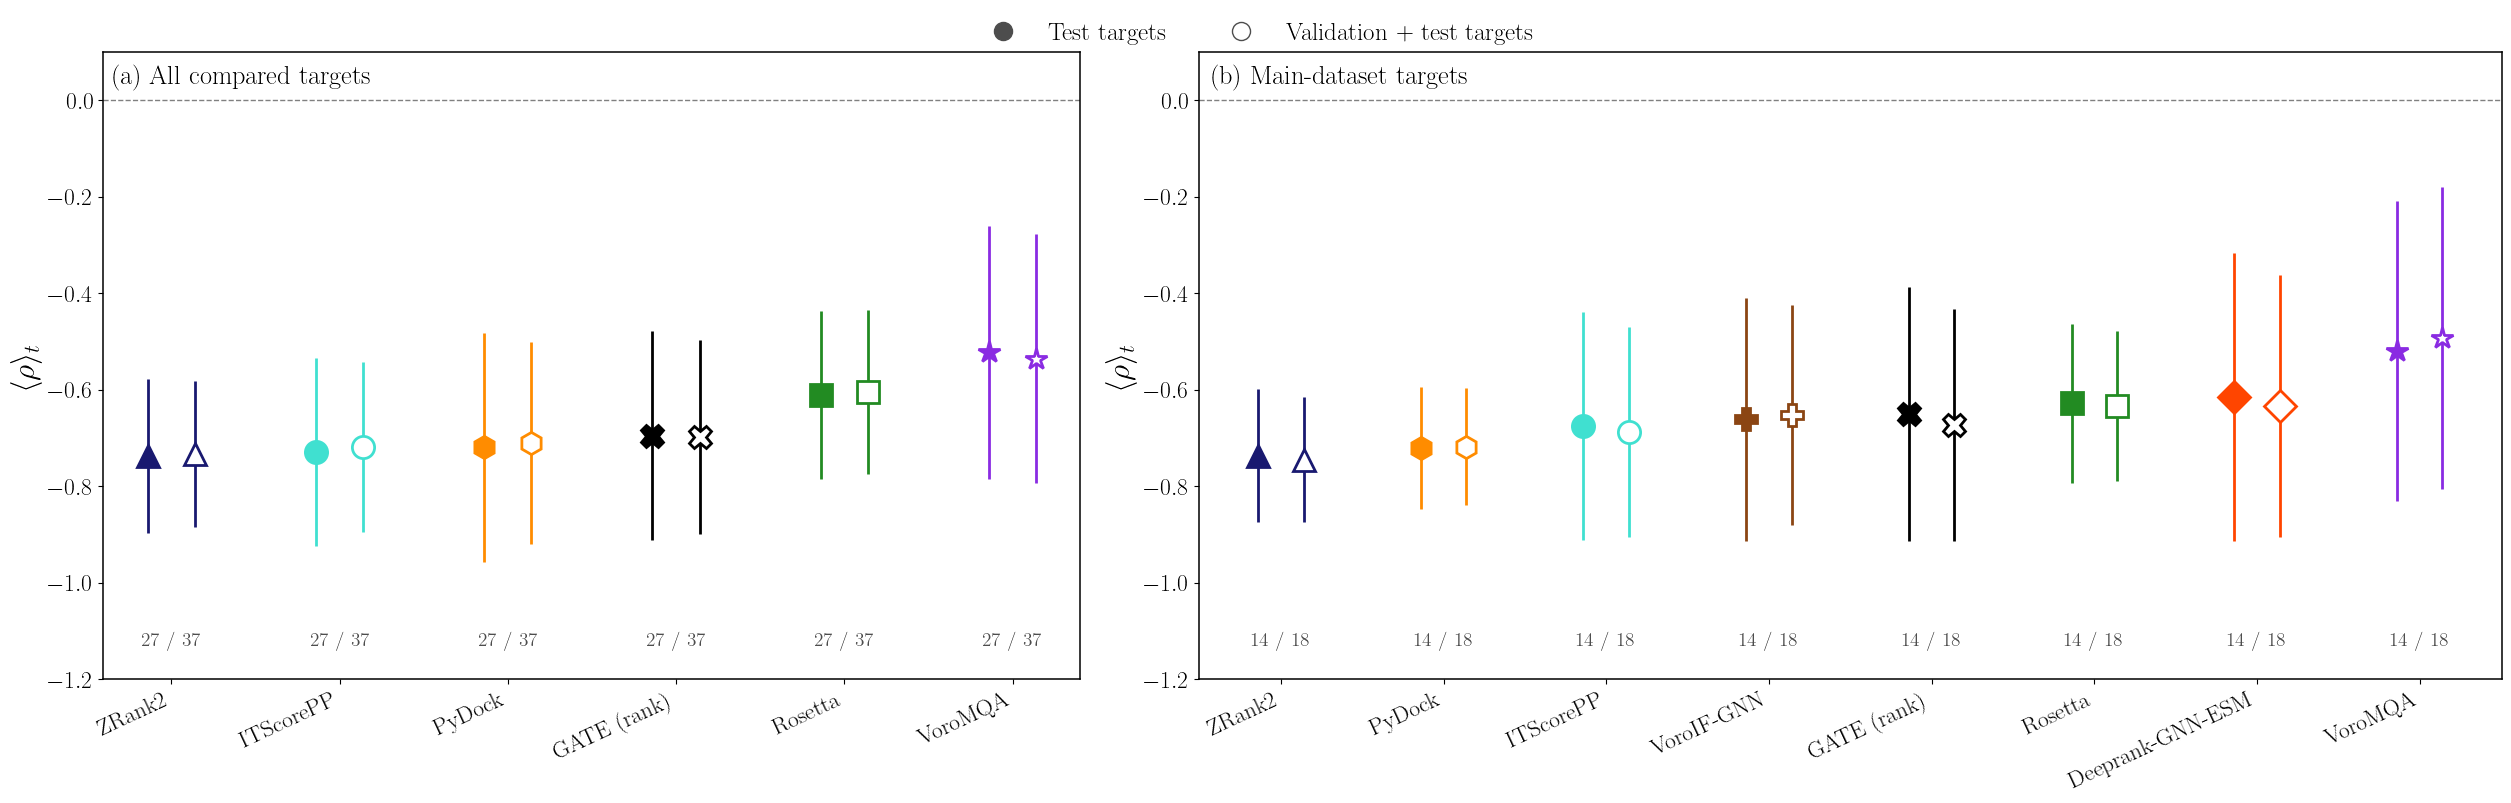

(a) All compared targets  (n = targets: test / validation + test, shown under each method)


test            validation + test           
            mean     sd   n              mean     sd   n
method                                                  
ZRank2    -0.737  0.160  27            -0.732  0.151  37
ITScorePP -0.729  0.195  27            -0.719  0.176  37
PyDock    -0.719  0.238  27            -0.710  0.210  37
GATE      -0.695  0.217  27            -0.698  0.201  37
Rosetta   -0.611  0.174  27            -0.605  0.170  37
VoroMQA   -0.522  0.262  27            -0.535  0.259  37

(b) Main-dataset targets  (n = targets: test / validation + test, shown under each method)


test            validation + test           
                   mean     sd   n              mean     sd   n
method                                                         
ZRank2           -0.736  0.138  14            -0.745  0.129  18
PyDock           -0.721  0.127  14            -0.718  0.121  18
ITScorePP        -0.675  0.236  14            -0.687  0.218  18
VoroIF-GNN       -0.661  0.252  14            -0.652  0.228  18
GATE             -0.650  0.264  14            -0.673  0.240  18
Rosetta          -0.628  0.164  14            -0.633  0.155  18
Deeprank-GNN-ESM -0.615  0.299  14            -0.634  0.271  18
VoroMQA          -0.520  0.310  14            -0.492  0.313  18

In [16]:
STYLE = {'ZRank2': dict(marker='^', color='#191970'), 'ITScorePP': dict(marker='o', color='#40E0D0'),
         'Rosetta': dict(marker='s', color='#228B22'), 'PyDock': dict(marker='h', color='#FF8C00'),
         'VoroMQA': dict(marker='*', color='#8A2BE2'), 'Deeprank-GNN-ESM': dict(marker='D', color='#FF4500'),
         'VoroIF-GNN': dict(marker='P', color='#8B4513'), 'GATE': dict(marker='X', color='black')}
MLABEL = {m: m for m in METHODS}; MLABEL['GATE'] = 'GATE (rank)'

def summary(sub):
    g = sub.groupby('method').rho
    return pd.DataFrame(dict(mean=g.mean(), sd=g.std(), n=g.size()))

panels = [('(a) All compared targets', comp[comp.method.isin(CLASSICAL + ['GATE'])]),
          ('(b) Main-dataset targets', comp[comp.source == 'main'])]
fig, axes = plt.subplots(1, 2, figsize=(25, 8), gridspec_kw=dict(width_ratios=[6, 8]), constrained_layout=True)
tables = {}
for ax, (title, sub) in zip(axes, panels):
    st, sa = summary(sub[sub.split == 'test']), summary(sub)
    order = st['mean'].sort_values().index.tolist()
    tables[title] = pd.concat({'test': st, 'validation + test': sa}, axis=1).loc[order]
    for i, m in enumerate(order):
        for dx, s_, face in [(-.14, st, STYLE[m]['color']), (.14, sa, 'white')]:
            ax.errorbar(i + dx, s_.loc[m, 'mean'], yerr=s_.loc[m, 'sd'], fmt=STYLE[m]['marker'], ms=16, color=STYLE[m]['color'],
                        mfc=face, mec=STYLE[m]['color'], mew=2, capsize=0, elinewidth=2)
        ax.text(i, -1.13, f"{int(st.loc[m, 'n'])} / {int(sa.loc[m, 'n'])}", ha='center', fontsize=14, color='0.3')
    ax.set_xticks(range(len(order)), [MLABEL[m] for m in order], rotation=25, ha='right', fontsize=17)
    ax.set_ylim(-1.2, 0.1); ax.axhline(0, color='0.5', lw=1, ls='--')
    ax.set_ylabel(r'$\langle \rho \rangle_t$')
    ax.text(0.01, 0.98, title, transform=ax.transAxes, va='top', fontsize=19)
from matplotlib.lines import Line2D
fig.legend([Line2D([], [], marker='o', color='0.3', ls='', ms=13), Line2D([], [], marker='o', color='0.3', mfc='white', ls='', ms=13)],
           ['Test targets', 'Validation + test targets'], loc='outside upper center', ncol=2, frameon=False, fontsize=18)
save(fig, 'scoring_functions_average_rho')
for title, tab in tables.items():
    print(title + '  (n = targets: test / validation + test, shown under each method)'); display(tab.round(3))

### Standalone: main-dataset targets

Same data as panel (b), validation and test targets pooled: one marker per scoring function at
$\langle\rho\rangle_t$ averaged over targets, vertical lines $\pm 1$ SD over targets, ordered best to worst.

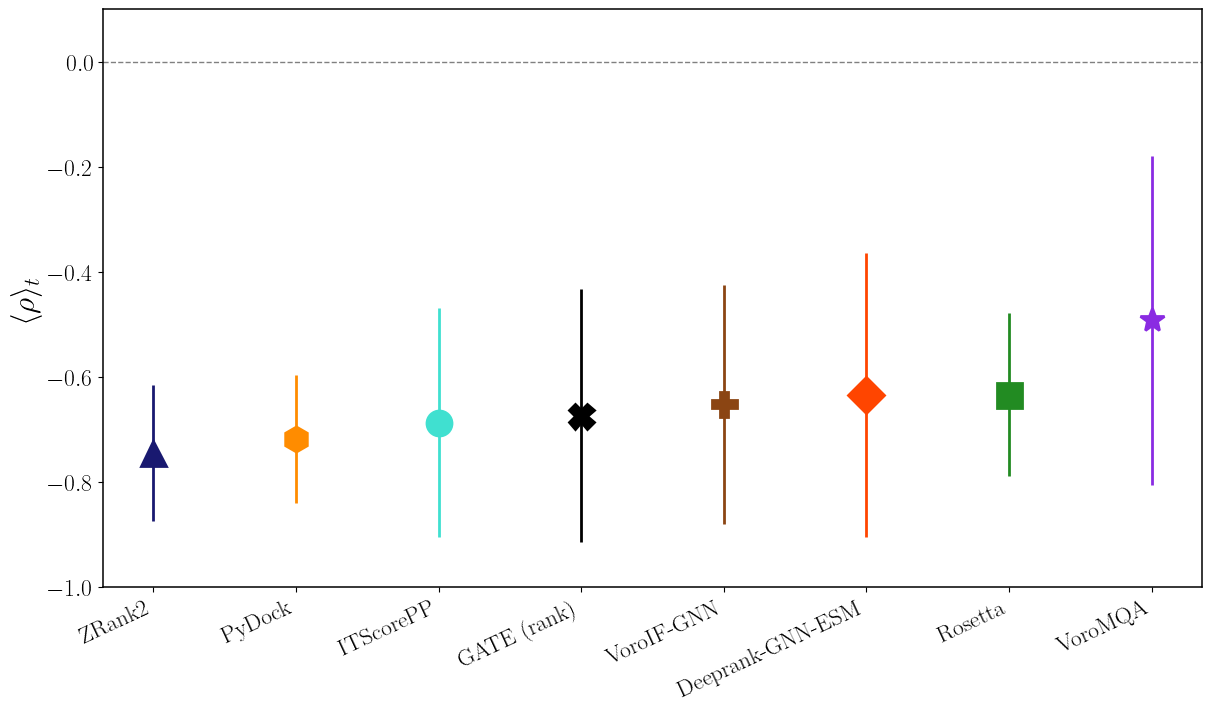

,mean,sd,n
method,,,
ZRank2,-0.745,0.129,18
PyDock,-0.718,0.121,18
ITScorePP,-0.687,0.218,18
GATE,-0.673,0.240,18
VoroIF-GNN,-0.652,0.228,18
Deeprank-GNN-ESM,-0.634,0.271,18
Rosetta,-0.633,0.155,18
VoroMQA,-0.492,0.313,18


In [17]:
main = summary(comp[comp.source == 'main'])
order = main['mean'].sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
for i, m in enumerate(order):
    ax.errorbar(i, main.loc[m, 'mean'], yerr=main.loc[m, 'sd'], fmt=STYLE[m]['marker'], ms=18, color=STYLE[m]['color'],
                mfc=STYLE[m]['color'], mec=STYLE[m]['color'], mew=2, capsize=0, elinewidth=2)
ax.set_xticks(range(len(order)), [MLABEL[m] for m in order], rotation=25, ha='right', fontsize=17)
ax.set_ylim(-1.0, 0.1); ax.axhline(0, color='0.5', lw=1, ls='--')
ax.set_ylabel(r'$\langle \rho \rangle_t$')
save(fig, 'scoring_functions_average_rho_main')
display(main.loc[order].round(3))

### The rank model against each scoring function, target by target

For each method, the paired difference $\rho_{\rm GATE} - \rho_{\rm method}$ on the targets both scored (negative
means the rank model correlates better), averaged over test targets, with a 95\% bootstrap interval over targets,
and the number of targets where the rank model is better.

In [18]:
rng = np.random.default_rng(0)
pw = []
for split_set, label in [(['test'], 'test'), (['validation', 'test'], 'validation + test')]:
    sub = comp[comp.split.isin(split_set)].pivot_table(index='target', columns='method', values='rho')
    for m in METHODS[:-1]:
        both = sub[['GATE', m]].dropna()
        if len(both) < 3:
            continue
        d = (both.GATE - both[m]).to_numpy()
        boots = rng.choice(d, size=(10_000, len(d))).mean(1)
        pw.append(dict(targets=label, method=m, n=len(d), mean_diff=d.mean(), lo=np.percentile(boots, 2.5),
                       hi=np.percentile(boots, 97.5), gate_better=int((d < 0).sum())))
pw = pd.DataFrame(pw); pw.to_csv(EXPORT / 'scoring_functions_paired_vs_gate.csv', index=False)
display(pw.round(3))

,targets,method,n,mean_diff,lo,hi,gate_better
0,test,ZRank2,27,0.042,-0.018,0.102,12
1,test,ITScorePP,27,0.033,-0.001,0.071,9
2,test,Rosetta,27,-0.085,-0.156,-0.005,22
3,test,PyDock,27,0.024,-0.087,0.117,10
4,test,VoroMQA,27,-0.173,-0.284,-0.066,20
5,test,Deeprank-GNN-ESM,14,-0.035,-0.167,0.080,7
6,test,VoroIF-GNN,14,0.011,-0.168,0.166,6
7,validation + test,ZRank2,37,0.034,-0.013,0.082,17
8,validation + test,ITScorePP,37,0.021,-0.015,0.056,14
9,validation + test,Rosetta,37,-0.093,-0.150,-0.031,29


### Per-target $\rho$ for every scoring function

In the style of the manuscript's per-target figure: each column is one target, ordered by $\langle\rho\rangle$
averaged over the manuscript's scoring functions available for that target (ZRank2, ITScorePP, Rosetta, PyDock,
VoroMQA and, where allowed, Deeprank-GNN-ESM), shown as the black line with $\pm 1$ SD bars. The rank model
(black $\times$) and VoroIF-GNN are plotted on top but are not part of the average. Target labels in grey are
validation targets; black are test targets.

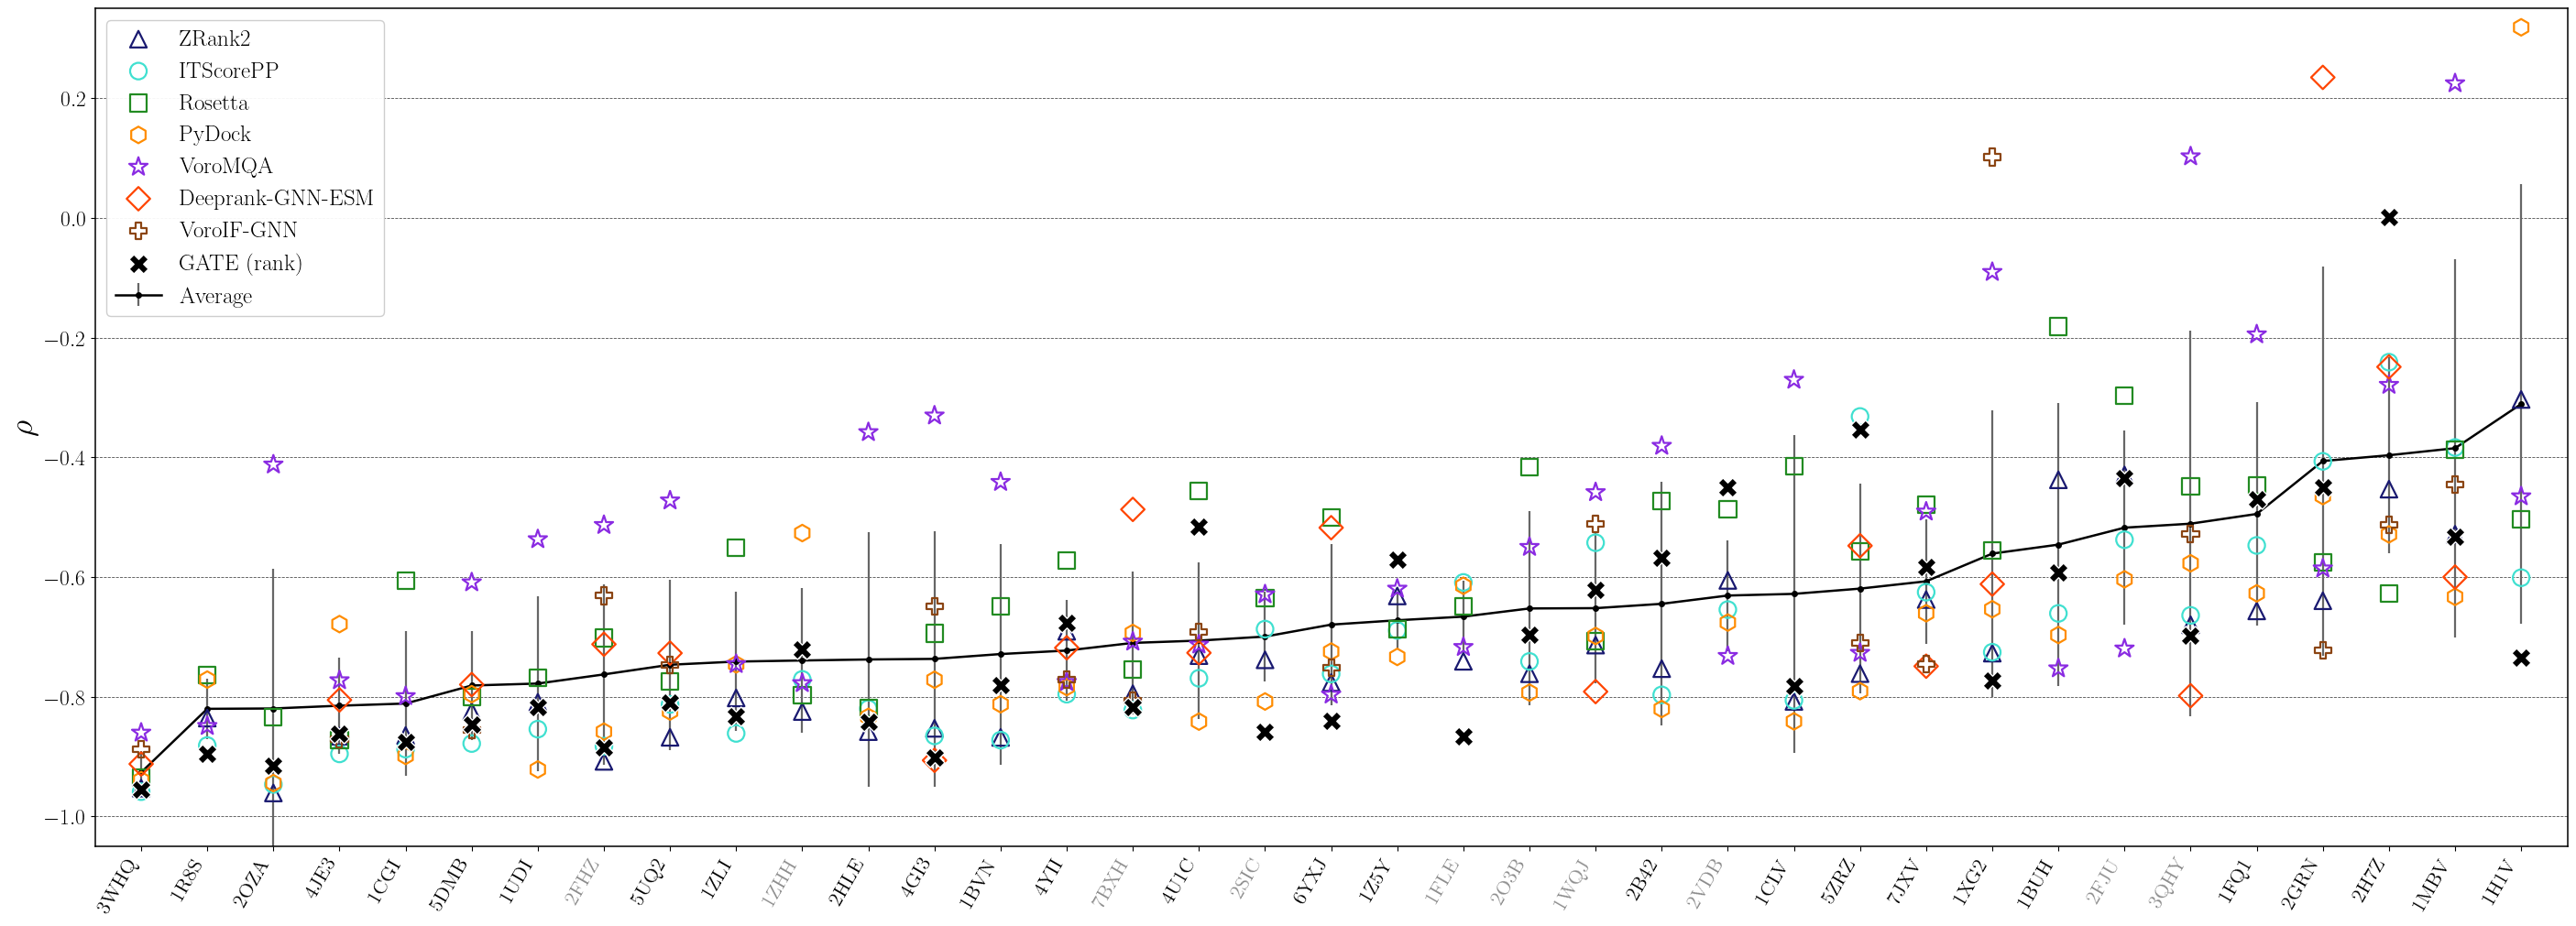

GATE (rank) beats the per-target average of the other methods on 25/37 targets (test: 19/27).


In [19]:
wide = comp.pivot_table(index='target', columns='method', values='rho')
ref_methods = CLASSICAL + ['Deeprank-GNN-ESM']
avg = wide[ref_methods].mean(axis=1); sd = wide[ref_methods].std(axis=1)
order = avg.sort_values().index
split_of = comp.drop_duplicates('target').set_index('target').split
with mpl.rc_context({'axes.labelsize': 26}):
    fig, ax = plt.subplots(figsize=(28, 10), constrained_layout=True)
    x = np.arange(len(order))
    for y in (-1, -0.8, -0.6, -0.4, -0.2, 0, 0.2):
        ax.axhline(y, color='0.3', ls='--', lw=.6, zorder=0)
    ax.errorbar(x, avg.loc[order], yerr=sd.loc[order], color='black', marker='.', ms=8, lw=1.8, ecolor='0.4',
                elinewidth=1.6, label='Average', zorder=2)
    for m in ref_methods + ['VoroIF-GNN']:
        v = wide.loc[order, m]
        ax.scatter(x, v, s=230 if m == 'VoroMQA' else 170, marker=STYLE[m]['marker'], facecolors='none',
                   edgecolors=STYLE[m]['color'], linewidths=1.6, label=MLABEL[m], zorder=3)
    ax.scatter(x, wide.loc[order, 'GATE'], s=230, marker='X', color='black', edgecolors='white', linewidths=1,
               label=MLABEL['GATE'], zorder=5)
    ax.set_xticks(x, [t.upper() for t in order], rotation=60, ha='right', fontsize=16)
    for lab, t in zip(ax.get_xticklabels(), order):
        lab.set_color('0.55' if split_of[t] == 'validation' else 'black')
    ax.set_xlim(-0.7, len(order) - 0.3); ax.set_ylim(-1.05, 0.35); ax.set_ylabel(r'$\rho$')
    ax.legend(loc='upper left', ncol=1, fontsize=18, frameon=True, framealpha=.95)
    save(fig, 'scoring_functions_rho_per_target')
print(f'GATE (rank) beats the per-target average of the other methods on {(wide.GATE < avg).sum()}/{len(avg)} targets '
      f"(test: {(wide.GATE < avg)[split_of[wide.index] == 'test'].sum()}/{(split_of[wide.index] == 'test').sum()}).")

### Observed vs predicted: GATE vs VoroIF-GNN on the main-dataset test targets

The 14 main-dataset test targets, where both models scored the same decoys. GATE (rank model, seed 17, as in the
earlier per-target figure) is in black; VoroIF-GNN in brown. VoroIF-GNN's score (`sum_of_gnn_scores`, the
summed predicted CAD-goodness) is not on a DockQ scale and grows with interface size, so within each target it is
min--max scaled to $[0, 1]$ (lowest-scoring decoy 0, highest 1). That scaling preserves each target's ordering, so its
$\rho$ is unchanged, but it is **not a calibration to DockQ**: only GATE's predictions are meant to lie on the
diagonal. Shared axes; the dashed line is perfect agreement; annotations give within-target Spearman $\rho$
(unoriented, i.e. positive is good, for both).

14 main-dataset test targets; decoys per target with both scores: 704--1372.


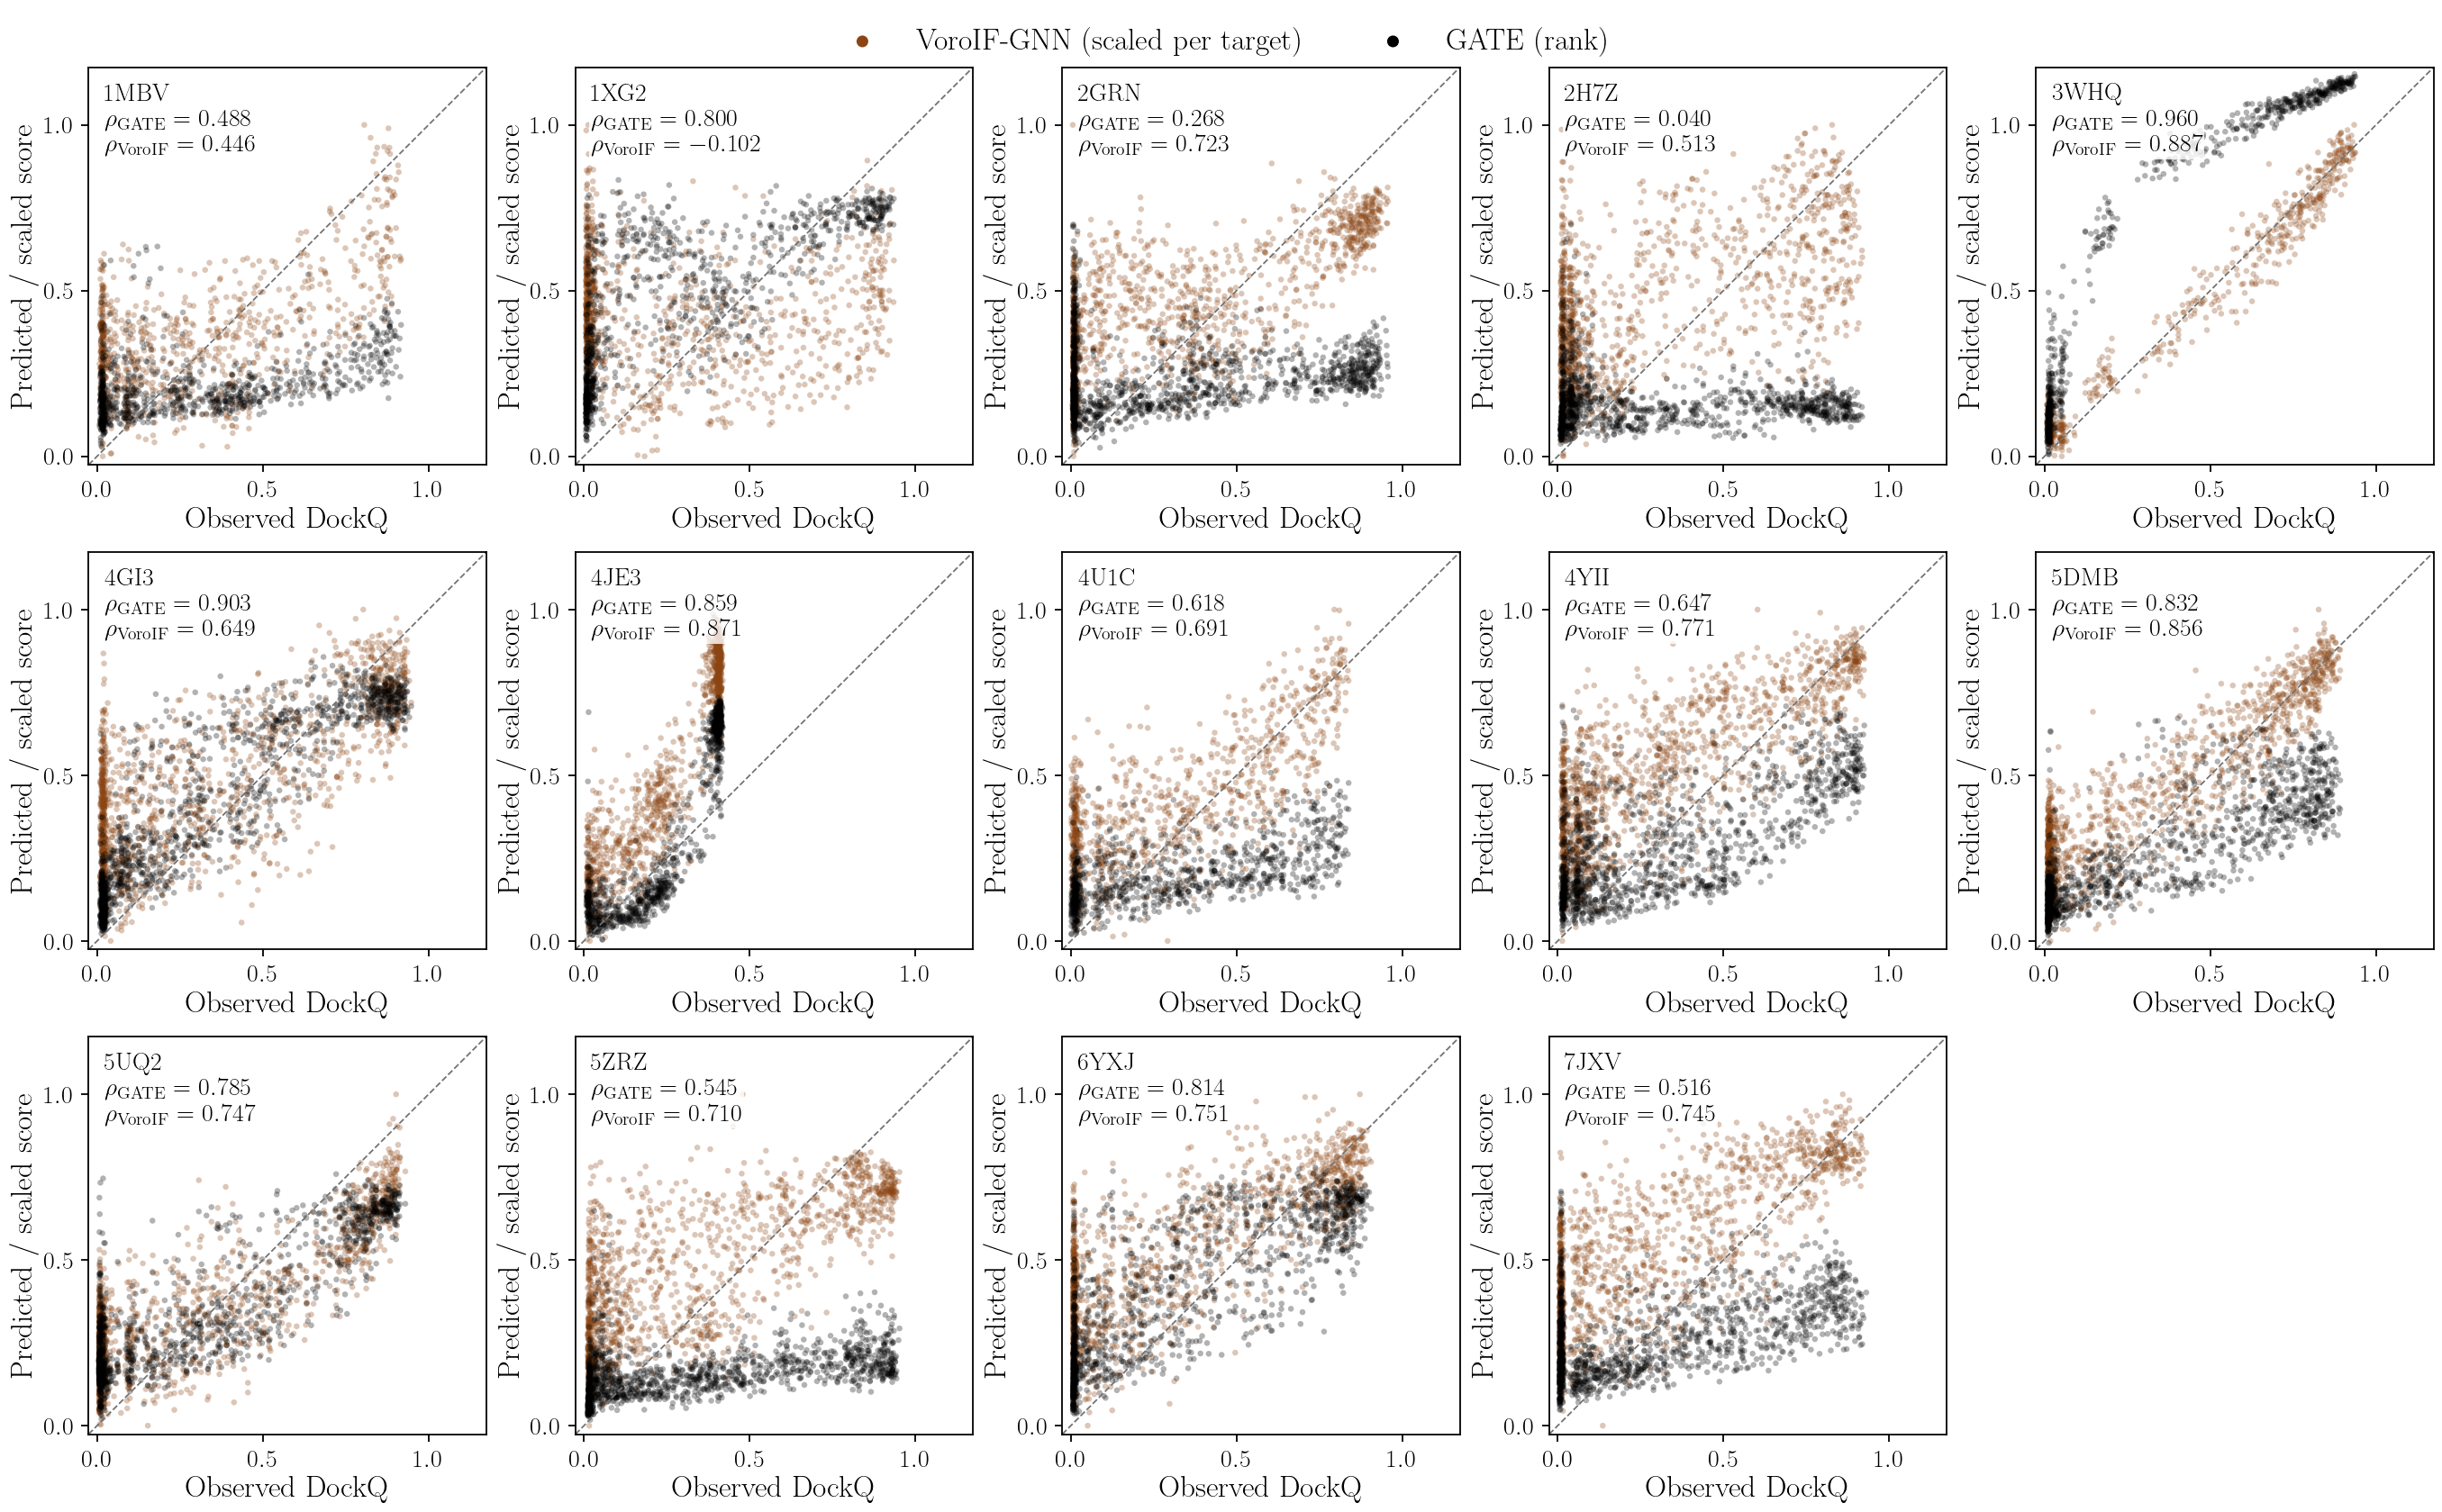

In [20]:
PANEL_SEED = 17
VOROIF_COLOR = '#8B4513'
main_test = sorted(comp[(comp.split == 'test') & (comp.source == 'main') & (comp.method == 'VoroIF-GNN')].target.unique())
frames = {}
for t in main_test:
    g = test_pred['rank', PANEL_SEED]
    g = g[g.target_id == t][['graph_name', 'true_target', 'predicted_target']]
    v = main_table(t)[0][['decoy', 'VoroIF-GNN']]
    j = g.merge(v, left_on='graph_name', right_on='decoy', how='inner').dropna(subset=['VoroIF-GNN'])
    lo, hi = j['VoroIF-GNN'].min(), j['VoroIF-GNN'].max()
    j['voroif_scaled'] = (j['VoroIF-GNN'] - lo) / (hi - lo)
    frames[t] = j
print(f'{len(main_test)} main-dataset test targets; decoys per target with both scores: '
      f"{min(len(f) for f in frames.values())}--{max(len(f) for f in frames.values())}.")
allj = pd.concat(frames.values())
axis_low = min(0.0, allj.predicted_target.min()) - 0.02
axis_high = max(1.0, allj.predicted_target.max()) + 0.02
ncols = 5; nrows = int(np.ceil(len(main_test) / ncols))
with mpl.rc_context({'axes.labelsize': 24, 'xtick.labelsize': 20, 'ytick.labelsize': 20}):
    fig, axes = plt.subplots(nrows, ncols, figsize=(27, 5.6 * nrows), sharex=True, sharey=True, constrained_layout=True)
    for ax, t in zip(axes.flat, main_test):
        j = frames[t]
        r_g = spearmanr(j.true_target, j.predicted_target).statistic
        r_v = spearmanr(j.true_target, j.voroif_scaled).statistic
        ax.scatter(j.true_target, j.voroif_scaled, color=VOROIF_COLOR, alpha=0.30, s=22, edgecolors='none', rasterized=True,
                   label='VoroIF-GNN (scaled per target)')
        ax.scatter(j.true_target, j.predicted_target, color='black', alpha=0.30, s=22, edgecolors='none', rasterized=True,
                   label='GATE (rank)')
        ax.plot([axis_low, axis_high], [axis_low, axis_high], color='0.45', ls='--', lw=1.3)
        ax.text(0.04, 0.96, t.upper() + '\n' + rf'$\rho_{{\mathrm{{GATE}}}} = {r_g:.3f}$' + '\n'
                + rf'$\rho_{{\mathrm{{VoroIF}}}} = {r_v:.3f}$', transform=ax.transAxes, ha='left', va='top', fontsize=20,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
        ax.set(xlim=(axis_low, axis_high), ylim=(axis_low, axis_high), xlabel='Observed DockQ', ylabel='Predicted / scaled score')
        ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1]); ax.set_aspect('equal', adjustable='box')
        ax.tick_params(labelbottom=True, labelleft=True, length=6, width=1.3, pad=6)
        for spine in ax.spines.values():
            spine.set_linewidth(1.3)
    for ax in list(axes.flat)[len(main_test):]:
        ax.set_visible(False)
    legend = fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='outside upper center', ncol=2, fontsize=24,
                        frameon=False, markerscale=2)
    for handle in legend.legend_handles:
        handle.set_alpha(1.0)
    save(fig, f'test_per_target_gate_vs_voroif_seed{PANEL_SEED}')

### What the comparison shows

- **The rank model is competitive with the best classical scoring functions, not ahead of them.** On the 27 test
  targets its $\langle\rho\rangle_t = -0.695$, fourth of six behind ZRank2 ($-0.737$), ITScorePP ($-0.729$) and
  PyDock ($-0.719$). Its paired differences from those three are not significant (intervals include zero), while it
  is clearly better than Rosetta ($-0.611$) and VoroMQA ($-0.522$).
- **Among GNN scoring functions it is level with the others.** On the main-dataset targets, where all can be
  compared: rank model $-0.650$, VoroIF-GNN $-0.661$, Deeprank-GNN-ESM $-0.615$ on test; none of the paired
  differences is significant on 14 targets.
- **It is better than the field on most targets but fails badly on a few.** The rank model beats the per-target
  average of the other methods on 19 of 27 test targets, including several hard ones (1H1V, 1FLE, 6YXJ, 2SIC). Its
  mean is pulled down by a few targets where it is near zero or far behind (2H7Z $\rho \approx 0$, 5ZRZ), which is
  why its spread over targets is among the largest. Fixing those failures matters more than raising the typical case.
- These $\rho$ values are on each target's distinct decoys as scored by the rank model; recomputed on the full
  supersampled tables, the classical functions reproduce the manuscript exactly, and using our decoys changes them by
  0.006 on average. VoroIF-GNN's training data were not checked for overlap with these targets.

## Readout

In [21]:
def ms(split, c, col, f='.4f', scale=1):
    return f"{agg.loc[(split, c), (col, 'mean')] * scale:{f}} ± {agg.loc[(split, c), (col, 'std')] * scale:{f}}"
lines = ['| config | val MSE | test MSE | val ⟨ρ⟩ | test ⟨ρ⟩ | test top-1 | test high recall / precision | test high bias |',
         '|---|---|---|---|---|---|---|---|']
for c in CONFIGS:
    lines.append(f"| {c} | {ms('validation', c, 'mse')} | {ms('test', c, 'mse')} | {ms('validation', c, 'macro_rho', '.3f')} | "
                 f"{ms('test', c, 'macro_rho', '.3f')} | {ms('test', c, 'top1', '.3f')} | "
                 f"{agg.loc[('test', c), ('high_recall', 'mean')] * 100:.1f}% / {agg.loc[('test', c), ('high_precision', 'mean')] * 100:.0f}% | "
                 f"{ms('test', c, 'high_bias', '.3f')} |")
lines += ['', f"Test references: constant-predictor MSE {REF['test']['const_mse']:.4f}; random / oracle top-1 "
          f"{REF['test']['random_top1']:.3f} / {REF['test']['oracle_top1']:.3f}.", '',
          'Same test targets, earlier recipe (seed mean):']
for mname in ba.index:
    lines.append(f"- {mname}: MSE {ba.loc[mname, ('mse', 'mean')]:.4f}, ⟨ρ⟩ {ba.loc[mname, ('macro_rho', 'mean')]:.3f}, "
                 f"top-1 {ba.loc[mname, ('top1', 'mean')]:.3f}, high bias {ba.loc[mname, ('high_bias', 'mean')]:.3f}")
e = eff.set_index(['config', 'metric'])
lines += ['', 'Paired vs rank on the 29 test targets (95% bootstrap CI; positive favours the configuration):']
for c in CONFIGS[1:]:
    lines.append(f"- {c}: −ΔMSE {e.loc[(c, 'mse'), 'mean']:+.4f} [{e.loc[(c, 'mse'), 'lo']:+.4f}, {e.loc[(c, 'mse'), 'hi']:+.4f}]; "
                 f"Δρ {e.loc[(c, 'rho'), 'mean']:+.3f} [{e.loc[(c, 'rho'), 'lo']:+.3f}, {e.loc[(c, 'rho'), 'hi']:+.3f}]")
text = '\n'.join(lines); display(Markdown(text)); (EXPORT / 'readout.md').write_text(text)

| config | val MSE | test MSE | val ⟨ρ⟩ | test ⟨ρ⟩ | test top-1 | test high recall / precision | test high bias |
|---|---|---|---|---|---|---|---|
| rank | 0.0470 ± 0.0006 | 0.0586 ± 0.0024 | 0.728 ± 0.012 | 0.686 ± 0.014 | 0.447 ± 0.020 | 9.2% / 49% | -0.298 ± 0.001 |
| rank_capri | 0.0455 ± 0.0033 | 0.0599 ± 0.0010 | 0.736 ± 0.013 | 0.676 ± 0.005 | 0.469 ± 0.027 | 7.0% / 45% | -0.307 ± 0.026 |
| rank_lambda3 | 0.0494 ± 0.0019 | 0.0606 ± 0.0018 | 0.710 ± 0.021 | 0.659 ± 0.019 | 0.407 ± 0.016 | 4.6% / 45% | -0.314 ± 0.040 |
| rank_lr1e-4 | 0.0460 ± 0.0010 | 0.0604 ± 0.0013 | 0.724 ± 0.005 | 0.661 ± 0.008 | 0.435 ± 0.006 | 12.7% / 49% | -0.263 ± 0.015 |

Test references: constant-predictor MSE 0.0967; random / oracle top-1 0.334 / 0.905.

Same test targets, earlier recipe (seed mean):
- Ladder, core: MSE 0.1070, ⟨ρ⟩ 0.553, top-1 0.319, high bias -0.538
- Ladder, all features: MSE 0.0808, ⟨ρ⟩ 0.644, top-1 0.454, high bias -0.401
- Rank (this experiment): MSE 0.0586, ⟨ρ⟩ 0.686, top-1 0.447, high bias -0.298

Paired vs rank on the 29 test targets (95% bootstrap CI; positive favours the configuration):
- rank_capri: −ΔMSE -0.0013 [-0.0050, +0.0022]; Δρ -0.010 [-0.031, +0.009]
- rank_lambda3: −ΔMSE -0.0017 [-0.0047, +0.0011]; Δρ -0.026 [-0.042, -0.011]
- rank_lr1e-4: −ΔMSE -0.0022 [-0.0053, +0.0009]; Δρ -0.025 [-0.043, -0.008]

1343

## Interpretation

**The new recipe generalizes to held-out targets.** On the same 29 test targets, the rank reference reaches test
DockQ MSE 0.059 against 0.081 for the all-features ladder model (and 0.107 for the core ladder): a 27\% reduction,
with seed spread four times smaller (SD 0.0024 vs 0.0097). Within-target ranking improves (test $\langle\rho\rangle$
0.686 vs 0.644, better on 19 of 29 targets, with the largest gains on the targets the ladder ranked worst), and the
under-prediction of high-quality decoys shrinks (bias $-0.30$ vs $-0.40$). Top-1 selection does not improve (0.447 vs
0.454; both well above the 0.334 random pick, far below the 0.905 oracle).

**Among the four configurations, the plain rank reference is best on test.** Paired over the 29 test targets, the
CAPRI head is a tie, and both $\lambda = 3$ and the lower learning rate rank decoys significantly worse ($\Delta\rho$
$\approx -0.025$, intervals excluding zero), with MSE tied. This is not the order the validation set suggested:
on validation the CAPRI head and the lower learning rate had the lowest MSE. Differences of 0.001--0.002 in
validation MSE between configurations do not carry over to test; the 12 validation targets have now guided
many rounds of choices and are no longer a reliable tie-breaker at that resolution.

**Validation is optimistic.** Every configuration is worse on test (MSE $\approx$0.059--0.061 vs 0.046--0.049;
the test labels are also slightly more spread out, constant-predictor MSE 0.097 vs 0.090). The share of
predicted-high decoys that are truly high falls from 58--90\% on validation to 45--49\% on test.

**High-quality decoys are still compressed.** Mean error on true highs is $-0.26$ to $-0.31$ on test, and at most
13\% of them are predicted $\geq 0.80$. The lower learning rate catches the most (12.7\% at unchanged precision,
bias $-0.26$) but ranks worse overall. The CAPRI head's P(high) again identifies high decoys no better than the
predicted DockQ (test ROC AUC 0.81 for both).

**Learning rate.** A peak of $10^{-4}$ makes the early validation curve somewhat less noisy (median change between
validations 0.0021 vs 0.0027) and moves the best checkpoint to a similar epoch, but brings no test benefit. The
learning rate is not what limits the model.

**Reconstruction has degraded.** At these checkpoints the autoencoder reconstructs amino-acid identity on test far
worse than the ladder models did (26--42\% vs 87\%) and edges somewhat worse (edge $F_1$ 61--73\% vs 78\%), while
C$\alpha$ distances are reconstructed much better (MAE 0.72--0.92 vs 1.22 \AA). Under fixed loss weights the
reconstruction term is dominated by the C$\alpha$-distance error (in \AA$^2$), so residue identity receives very
little training signal; the ladder's adaptive shares gave node reconstruction a fixed 15\% of the loss.
$\lambda = 3$ recovers some identity accuracy (42\%). If the structural reconstruction matters for its own sake,
the reconstruction terms need rebalancing among themselves (for example standardizing C$\alpha$ distance or
re-weighting node vs edge terms), separately from the DockQ-vs-reconstruction weight.

Caveats: three seeds; these test numbers are now spent for this set of choices. Any further tuning should be judged
on validation (or on new splits), with the test set held for a final, pre-registered comparison.